# Notebook 01 — Complete Data Preparation Pipeline
## University RAG

This notebook builds a **complete, automatic, and reproducible data engineering pipeline** for Persian university documents.

### 🎯 Goal
Convert raw university PDF files into:

- raw and normalized text for each page
- automatic detection of text-based, scanned, and suspicious pages
- selective OCR only when it is needed
- document, page, and chunk metadata
- structure-aware chunks between 300 and 500 tokens
- quality, error, and reproducibility reports

### 📥 Input

```text
data/raw/
├── exams/
├── master_phd/
├── phd/
├── regulations/
├── transfer/
├── tuition/
└── undergraduate/
```

### 📤 Output

```text
document_catalog.csv
documents.parquet
pages.parquet
chunks.parquet
metadata.json
quality_report.json
execution_report.json
summary.json
final_document_status.csv
```

### 🧩 Position in the RAG Pipeline

```text
Raw PDFs
  ↓
Discovery and Catalog
  ↓
PDF and Page Analysis
  ↓
Direct Text Extraction
  ↓
Selective OCR
  ↓
Persian Text Cleaning
  ↓
Structure Detection
  ↓
Structure-aware Chunking
  ↓
Metadata, Validation, and Quality Report
  ↓
chunks.parquet → Notebook 02
```



# 1. Design Decisions

1. Use **PyMuPDF** to inspect PDF files and keep page-level information.
2. Run **selective OCR** only on scanned or suspicious pages.
3. Compare direct text and OCR text, then keep the better version.
4. Keep both `raw_text` and `normalized_text`.
5. Remove headers and footers only when they repeat across many pages.
6. Use **structure-aware chunking** and preserve chapters, sections, articles, notes, and clauses.
7. Continue processing even when one file is damaged.
8. Read paths and thresholds from `config.yaml`.
9. Save package versions, the random seed, runtime, errors, and warnings.


# 2. Environment, Configuration, and Reproducibility

> `pytesseract` is only a Python wrapper. For real OCR, the Tesseract program and the Persian language package `fas` must also be installed on Windows.


In [1]:
from __future__ import annotations

import contextlib
import hashlib
import importlib.metadata as importlib_metadata
import json
import logging
import math
import os
import platform
import random
import re
import shutil
import sys
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Optional

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import pytesseract
import yaml
from hazm import Normalizer, sent_tokenize, word_tokenize
from IPython.display import display
from tqdm.auto import tqdm

PIPELINE_STARTED_AT = time.perf_counter()
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()

In [2]:
def discover_project_root(start: Optional[Path] = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (
            (candidate / "notebooks").exists()
            or (candidate / "requirements.txt").exists()
        ):
            return candidate
    if start.name.lower() == "notebooks":
        return start.parent
    raise FileNotFoundError(
        "Project root was not found. Place the notebook inside University_RAG/notebooks "
        "and start Jupyter from the project root."
    )

PROJECT_ROOT = discover_project_root()
CONFIG_PATH = PROJECT_ROOT / "config.yaml"

DEFAULT_CONFIG = {
    "project": {"name": "University_RAG", "seed": 42, "language": "fa"},
    "paths": {
        "raw_data": "data/raw",
        "processed_data": "data/processed",
        "reports": "reports/data_preparation",
        "figures": "reports/data_preparation/figures",
        "logs": "logs",
    },
    "categories": [
        "exams", "master_phd", "phd", "regulations",
        "transfer", "tuition", "undergraduate",
    ],
    "pdf_analysis": {
        "min_direct_chars": 80,
        "min_direct_tokens": 15,
        "min_persian_ratio": 0.15,
        "suspicious_noise_ratio": 0.12,
    },
    "ocr": {
        "enabled": True, "language": "fas+eng", "dpi": 300,
        "psm": 6, "oem": 3, "minimum_confidence": 20,
        "preprocess": True, "deskew": True, "tesseract_cmd": "",
    },
    "cleaning": {
        "header_footer_candidate_lines": 3,
        "header_footer_min_pages": 3,
        "header_footer_repeat_ratio": 0.35,
    },
    "quality": {
        "minimum_page_tokens": 20,
        "ready_score": 60,
        "invalid_score": 25,
        "maximum_noise_ratio": 0.18,
        "maximum_replacement_ratio": 0.01,
    },
    "chunking": {
        "min_tokens": 300, "target_tokens": 400,
        "max_tokens": 500, "overlap_tokens": 80,
        "merge_small_non_structural_units": True,
    },
}

def deep_merge(default: dict, custom: dict) -> dict:
    result = dict(default)
    for key, value in (custom or {}).items():
        if isinstance(value, dict) and isinstance(result.get(key), dict):
            result[key] = deep_merge(result[key], value)
        else:
            result[key] = value
    return result

if not CONFIG_PATH.exists():
    CONFIG_PATH.write_text(
        yaml.safe_dump(DEFAULT_CONFIG, allow_unicode=True, sort_keys=False),
        encoding="utf-8",
    )

with CONFIG_PATH.open("r", encoding="utf-8") as f:
    CONFIG = deep_merge(DEFAULT_CONFIG, yaml.safe_load(f) or {})

SEED = int(CONFIG["project"]["seed"])
random.seed(SEED)
np.random.seed(SEED)

RAW_DIR = PROJECT_ROOT / CONFIG["paths"]["raw_data"]
PROCESSED_DIR = PROJECT_ROOT / CONFIG["paths"]["processed_data"]
REPORT_DIR = PROJECT_ROOT / CONFIG["paths"]["reports"]
FIGURES_DIR = PROJECT_ROOT / CONFIG["paths"]["figures"]
LOG_DIR = PROJECT_ROOT / CONFIG["paths"]["logs"]

for folder in [RAW_DIR, PROCESSED_DIR, REPORT_DIR, FIGURES_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print(yaml.safe_dump(CONFIG, allow_unicode=True, sort_keys=False))

PROJECT_ROOT: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG
project:
  name: University_RAG
  seed: 42
  language: fa
paths:
  raw_data: data/raw
  processed_data: data/processed
  reports: reports/data_preparation
  figures: reports/data_preparation/figures
  logs: logs
categories:
- exams
- master_phd
- phd
- regulations
- transfer
- tuition
- undergraduate
pdf_analysis:
  min_direct_chars: 80
  min_direct_tokens: 15
  min_persian_ratio: 0.15
  suspicious_noise_ratio: 0.12
ocr:
  enabled: true
  language: fas+eng
  dpi: 300
  psm: 6
  oem: 3
  minimum_confidence: 20
  preprocess: true
  deskew: true
  tesseract_cmd: C:\Program Files\Tesseract-OCR\tesseract.exe
cleaning:
  header_footer_candidate_lines: 3
  header_footer_min_pages: 3
  header_footer_repeat_ratio: 0.35
quality:
  minimum_page_tokens: 20
  ready_score: 60
  invalid_score: 25
  maximum_noise_ratio: 0.18
  maximum_replacement_ratio: 0.01
chunking:
  min_tokens: 300
  target_tokens: 400
  max_tokens: 500
  overlap_tokens: 80

In [3]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
LOG_PATH = LOG_DIR / f"data_preparation_{RUN_ID}.log"

logger = logging.getLogger("UniversityRAG.DataPreparation")
logger.setLevel(logging.INFO)
logger.handlers.clear()

file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
file_handler.setFormatter(logging.Formatter(
    "%(asctime)s | %(levelname)s | %(message)s"
))
logger.addHandler(file_handler)

stream_handler = logging.StreamHandler(sys.stdout)
stream_handler.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
logger.addHandler(stream_handler)

STAGE_TIMINGS: dict[str, float] = {}
PIPELINE_ERRORS: list[dict[str, Any]] = []
PIPELINE_WARNINGS: list[dict[str, Any]] = []

@contextlib.contextmanager
def timed_stage(name: str):
    start = time.perf_counter()
    logger.info("START STAGE: %s", name)
    try:
        yield
    finally:
        elapsed = round(time.perf_counter() - start, 3)
        STAGE_TIMINGS[name] = elapsed
        logger.info("END STAGE: %s | %.3f sec", name, elapsed)

def record_error(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage, "message": str(message), "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_ERRORS.append(item)
    logger.error("%s | %s | %s", stage, message, context)

def record_warning(stage: str, message: str, **context: Any) -> None:
    item = {
        "stage": stage, "message": str(message), "context": context,
        "timestamp": datetime.now(timezone.utc).isoformat(),
    }
    PIPELINE_WARNINGS.append(item)
    logger.warning("%s | %s | %s", stage, message, context)

logger.info("Pipeline initialized. Run ID: %s", RUN_ID)

INFO | Pipeline initialized. Run ID: 20260714_232636


## 2.1. Preflight Check

This step checks:

- required Python packages
- `pyarrow` for Parquet output
- the Tesseract OCR engine
- the Persian language package `fas`
- common Tesseract installation paths on Windows


In [4]:
REQUIRED_PACKAGES = [
    "PyMuPDF", "pandas", "numpy", "matplotlib", "hazm",
    "tqdm", "pytesseract", "Pillow", "opencv-python",
    "PyYAML", "pyarrow",
]

def package_version(name: str) -> Optional[str]:
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return None

PACKAGE_VERSIONS = {name: package_version(name) for name in REQUIRED_PACKAGES}
missing_packages = [name for name, version in PACKAGE_VERSIONS.items() if version is None]

if missing_packages:
    print("Missing packages:", missing_packages)
else:
    print("All required packages are installed.")

def configure_tesseract(config: dict) -> tuple[bool, list[str], Optional[str]]:
    requested = str(config["ocr"].get("tesseract_cmd", "")).strip()
    candidates = []
    if requested:
        candidates.append(Path(requested))
    candidates.extend([
        Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe"),
        Path(r"C:\Program Files (x86)\Tesseract-OCR\tesseract.exe"),
        Path.home() / "AppData/Local/Programs/Tesseract-OCR/tesseract.exe",
    ])

    for candidate in candidates:
        if candidate.exists():
            pytesseract.pytesseract.tesseract_cmd = str(candidate)
            break

    try:
        version = str(pytesseract.get_tesseract_version())
        languages = sorted(pytesseract.get_languages(config=""))
        return True, languages, version
    except Exception as exc:
        record_warning(
            "preflight",
            "Tesseract OCR is not available. Scanned pages will be marked for review.",
            error=str(exc),
        )
        return False, [], None

OCR_ENGINE_AVAILABLE, TESSERACT_LANGUAGES, TESSERACT_VERSION = configure_tesseract(CONFIG)
OCR_REQUESTED_LANGUAGE = CONFIG["ocr"]["language"]
OCR_LANGUAGE_PARTS = [x.strip() for x in OCR_REQUESTED_LANGUAGE.split("+") if x.strip()]
OCR_LANGUAGES_AVAILABLE = all(x in TESSERACT_LANGUAGES for x in OCR_LANGUAGE_PARTS)
OCR_AVAILABLE = (
    bool(CONFIG["ocr"]["enabled"])
    and OCR_ENGINE_AVAILABLE
    and OCR_LANGUAGES_AVAILABLE
)

print("Tesseract engine:", OCR_ENGINE_AVAILABLE)
print("Tesseract version:", TESSERACT_VERSION)
print("Requested language:", OCR_REQUESTED_LANGUAGE)
print("OCR available:", OCR_AVAILABLE)

if "pyarrow" in [x.lower() for x in missing_packages]:
    raise ModuleNotFoundError(
        "To create Parquet files, run: pip install pyarrow\n"
        "Then restart the kernel and run all notebook cells again."
    )

ENVIRONMENT_INFO = {
    "run_id": RUN_ID,
    "run_started_utc": RUN_STARTED_UTC,
    "python_version": sys.version,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "project_root": str(PROJECT_ROOT),
    "config_path": str(CONFIG_PATH),
    "seed": SEED,
    "package_versions": PACKAGE_VERSIONS,
    "tesseract_available": OCR_ENGINE_AVAILABLE,
    "tesseract_version": TESSERACT_VERSION,
    "tesseract_languages": TESSERACT_LANGUAGES,
    "ocr_available": OCR_AVAILABLE,
}
display(pd.DataFrame([ENVIRONMENT_INFO]).T.rename(columns={0: "value"}))

All required packages are installed.
Tesseract engine: True
Tesseract version: 5.4.0.20240606
Requested language: fas+eng
OCR available: True


,value
run_id,20260714_232636
run_started_utc,2026-07-14T19:56:31.133477+00:00
python_version,"3.11.3 (tags/v3.11.3:f3909b8, Apr 4 2023, 23:..."
python_executable,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\.v...
platform,Windows-10-10.0.26200-SP0
machine,AMD64
project_root,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG
config_path,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\co...
seed,42
package_versions,"{'PyMuPDF': '1.28.0', 'pandas': '3.0.3', 'nump..."


# 3. Dataset and Official Source

Official document source:

`https://eduservice.uk.ac.ir/regulations`

| Folder | Meaning |
|---|---|
| `regulations` | General regulations and procedures |
| `exams` | Exam rules and instructions |
| `undergraduate` | Undergraduate documents |
| `master_phd` | Master's and general PhD documents |
| `phd` | PhD-specific documents |
| `transfer` | Guest student and transfer rules |
| `tuition` | Tuition-paying student documents |


# 4. File Discovery and Initial Catalog

This step:

- searches all subfolders for PDF files
- calculates SHA-256 for each file
- creates a stable `document_id`
- detects duplicate files
- stores category, path, file size, and modification time


In [5]:
PERSIAN_DIGITS = "۰۱۲۳۴۵۶۷۸۹"
ARABIC_DIGITS = "٠١٢٣٤٥٦٧٨٩"
LATIN_DIGITS = "0123456789"
DIGIT_TRANSLATION = str.maketrans(
    PERSIAN_DIGITS + ARABIC_DIGITS,
    LATIN_DIGITS + LATIN_DIGITS,
)

def file_sha256(path: Path, block_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as f:
        while block := f.read(block_size):
            digest.update(block)
    return digest.hexdigest()

def normalized_relative_path(path: Path, root: Path) -> str:
    try:
        return path.resolve().relative_to(root.resolve()).as_posix()
    except ValueError:
        return path.resolve().as_posix()

def clean_filename_title(filename: str) -> str:
    title = Path(filename).stem
    title = re.sub(r"[_\-]+", " ", title)
    return re.sub(r"\s+", " ", title).strip()

with timed_stage("document_discovery"):
    pdf_paths = sorted(
        {
            p.resolve()
            for p in RAW_DIR.rglob("*")
            if p.is_file() and p.suffix.lower() == ".pdf"
        },
        key=lambda p: p.as_posix().lower(),
    )

    if not pdf_paths:
        raise FileNotFoundError(
            f"No PDF files were found in {RAW_DIR}."
        )

    catalog_rows = []
    seen_hashes = {}

    for path in tqdm(pdf_paths, desc="Building document catalog"):
        try:
            sha256 = file_sha256(path)
            document_id = f"doc_{sha256[:16]}"
            duplicate_of = seen_hashes.get(sha256)
            if duplicate_of is None:
                seen_hashes[sha256] = document_id

            stat = path.stat()
            catalog_rows.append({
                "document_id": document_id,
                "filename": path.name,
                "title_from_filename": clean_filename_title(path.name),
                "category": path.parent.name,
                "absolute_path": str(path),
                "relative_path": normalized_relative_path(path, PROJECT_ROOT),
                "file_size_bytes": int(stat.st_size),
                "file_size_mb": round(stat.st_size / (1024 ** 2), 4),
                "modified_time": datetime.fromtimestamp(
                    stat.st_mtime, tz=timezone.utc
                ).isoformat(),
                "sha256": sha256,
                "is_duplicate": duplicate_of is not None,
                "duplicate_of": duplicate_of,
            })
        except Exception as exc:
            record_error("document_discovery", str(exc), path=str(path))

catalog_df = pd.DataFrame(catalog_rows).sort_values(
    ["category", "filename"], kind="stable"
).reset_index(drop=True)

print("PDFs discovered:", len(catalog_df))
print("Unique PDFs:", int((~catalog_df["is_duplicate"]).sum()))
print("Duplicates:", int(catalog_df["is_duplicate"].sum()))
display(catalog_df.head(15))

INFO | START STAGE: document_discovery


Building document catalog:   0%|          | 0/18 [00:00<?, ?it/s]

INFO | END STAGE: document_discovery | 2.103 sec
PDFs discovered: 18
Unique PDFs: 15
Duplicates: 3


,document_id,filename,title_from_filename,category,absolute_path,relative_path,file_size_bytes,file_size_mb,modified_time,sha256,is_duplicate,duplicate_of
0,doc_f5415ef9632df47d,دستورالعمل بررسی موارد غیبت پزشکی در امتحانات ...,دستورالعمل بررسی موارد غیبت پزشکی در امتحانات ...,exams,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/exams/دستورالعمل بررسی موارد غیبت پزش...,71148,0.0679,2026-07-14T18:39:30.111786+00:00,f5415ef9632df47de51f849fe7eb627442fe0d290a9c8a...,False,NaN
1,doc_6def6b6e442a995c,راهنمای شرکت در امتحانات پایان ترم.pdf,راهنمای شرکت در امتحانات پایان ترم,exams,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/exams/راهنمای شرکت در امتحانات پایان ...,215402,0.2054,2026-07-14T18:39:22.219222+00:00,6def6b6e442a995c7db963594f64cc62ba4b6256480f63...,False,NaN
2,doc_bbf18baa0e3e98b5,9172023 - آئین نامه دکتری عمومی دامپزشکی 1400.pdf,9172023 آئین نامه دکتری عمومی دامپزشکی 1400,master_phd,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/master_phd/9172023 - آئین نامه دکتری ...,1670955,1.5935,2026-07-14T18:41:00.349563+00:00,bbf18baa0e3e98b56c9978e28d1b5c0e5f4e40bed9fc29...,False,NaN
3,doc_49c5526926da11d9,ainname karshenasi phd msc 1397 (2).pdf,ainname karshenasi phd msc 1397 (2),master_phd,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/master_phd/ainname karshenasi phd msc...,2060530,1.9651,2026-07-14T18:40:55.235437+00:00,49c5526926da11d94db88c723a942b2f4de3a6fc3c05c8...,False,NaN
4,doc_8437d8390ee97a32,شیوه نامه ارشد 97.pdf,شیوه نامه ارشد 97,master_phd,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/master_phd/شیوه نامه ارشد 97.pdf,3503102,3.3408,2026-07-14T18:41:05.632138+00:00,8437d8390ee97a327de71b0baf49cb63bed92b324e5d28...,False,NaN
5,doc_49c5526926da11d9,ainname karshenasi phd msc 1397 (3).pdf,ainname karshenasi phd msc 1397 (3),phd,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/phd/ainname karshenasi phd msc 1397 (...,2060530,1.9651,2026-07-14T18:41:25.972108+00:00,49c5526926da11d94db88c723a942b2f4de3a6fc3c05c8...,True,doc_49c5526926da11d9
6,doc_9ec8a43cb4099b95,شیوه نامه دکتری تخصصی 1397.pdf,شیوه نامه دکتری تخصصی 1397,phd,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/phd/شیوه نامه دکتری تخصصی 1397.pdf,4591151,4.3785,2026-07-14T18:41:31.178641+00:00,9ec8a43cb4099b95143911134a934976c9d544a2a2ac54...,False,NaN
7,doc_49c5526926da11d9,ainname karshenasi phd msc 1397.pdf,ainname karshenasi phd msc 1397,regulations,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/regulations/ainname karshenasi phd ms...,2060530,1.9651,2026-07-14T18:37:56.761781+00:00,49c5526926da11d94db88c723a942b2f4de3a6fc3c05c8...,True,doc_49c5526926da11d9
8,doc_612061131248f51e,shivename 1402.pdf,shivename 1402,regulations,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/regulations/shivename 1402.pdf,10224480,9.7508,2026-07-14T18:37:50.641516+00:00,612061131248f51e6cedcee17a6d60a4e12f442efde527...,False,NaN
9,doc_75358f36febb3e54,خلاصه قوانین آموزشی.pdf,خلاصه قوانین آموزشی,regulations,D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\da...,data/raw/regulations/خلاصه قوانین آموزشی.pdf,96523,0.0921,2026-07-14T18:38:04.303357+00:00,75358f36febb3e5455f681faeb668cc6814ca3bda59b9a...,False,NaN


,category,pdf_count
3,regulations,5
1,master_phd,3
0,exams,2
2,phd,2
4,transfer,2
5,tuition,2
6,undergraduate,2


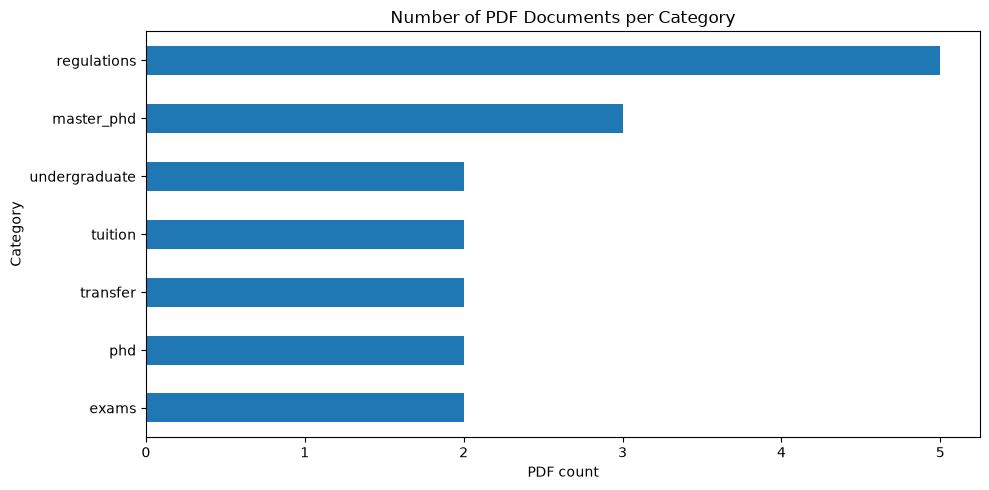

In [6]:
category_counts = (
    catalog_df.groupby("category", dropna=False)
    .size()
    .rename("pdf_count")
    .reset_index()
    .sort_values("pdf_count", ascending=False)
)
display(category_counts)

catalog_df.to_csv(
    PROCESSED_DIR / "document_catalog_initial.csv",
    index=False,
    encoding="utf-8-sig",
)

plt.figure(figsize=(10, 5))
category_counts.set_index("category")["pdf_count"].sort_values().plot(kind="barh")
plt.title("Number of PDF Documents per Category")
plt.xlabel("PDF count")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pdf_count_by_category.png", dpi=180, bbox_inches="tight")
plt.show()

# 5. Initial Document and Page Analysis

For each document, the notebook checks:

- whether the file can be opened
- whether it is encrypted
- page count and PDF metadata
- the number of text, scanned, and suspicious pages
- the final PDF type: `text`, `scanned`, `mixed`, `suspicious`, or `corrupt`

For each page, the notebook records:

- character and token count
- Persian character ratio
- noise and broken-encoding ratios
- image count
- whether OCR is needed


In [7]:
PERSIAN_CHAR_PATTERN = re.compile(r"[\u0600-\u06FF]")
LETTER_PATTERN = re.compile(r"[A-Za-z\u0600-\u06FF]")
STRUCTURE_PROTECTION_PATTERN = re.compile(
    r"^\s*(فصل|بخش|ماده|تبصره|بند)\b",
    flags=re.IGNORECASE,
)

def normalize_digits(text: str) -> str:
    return (text or "").translate(DIGIT_TRANSLATION)

def count_tokens(text: str) -> int:
    text = (text or "").strip()
    if not text:
        return 0
    try:
        return len(word_tokenize(text))
    except Exception:
        return len(text.split())

def persian_character_ratio(text: str) -> float:
    letters = LETTER_PATTERN.findall(text or "")
    if not letters:
        return 0.0
    return len(PERSIAN_CHAR_PATTERN.findall(text or "")) / len(letters)

def replacement_character_ratio(text: str) -> float:
    text = text or ""
    return text.count("\ufffd") / len(text) if text else 0.0

def control_character_ratio(text: str) -> float:
    text = text or ""
    if not text:
        return 0.0
    bad = sum(
        1 for ch in text
        if unicodedata.category(ch).startswith("C")
        and ch not in {"\n", "\t", "\u200c"}
    )
    return bad / len(text)

def noise_character_ratio(text: str) -> float:
    text = text or ""
    if not text:
        return 1.0
    allowed = set(" \n\t.,،؛;:!?؟()[]{}«»\"'/-_٪%+=×*#@\u200c")
    noisy = 0
    for ch in text:
        if ch.isalnum() or ch in allowed:
            continue
        if unicodedata.category(ch).startswith(("P", "S")):
            continue
        noisy += 1
    return noisy / len(text)

def direct_text_metrics(text: str) -> dict[str, Any]:
    return {
        "direct_char_count": len(text or ""),
        "direct_token_count": count_tokens(text),
        "direct_persian_ratio": round(persian_character_ratio(text), 4),
        "direct_noise_ratio": round(noise_character_ratio(text), 4),
        "direct_replacement_ratio": round(replacement_character_ratio(text), 6),
        "direct_control_ratio": round(control_character_ratio(text), 6),
    }

def classify_page_initial(metrics: dict, image_count: int) -> tuple[str, bool, list[str]]:
    reasons = []
    min_chars = int(CONFIG["pdf_analysis"]["min_direct_chars"])
    min_tokens = int(CONFIG["pdf_analysis"]["min_direct_tokens"])
    min_fa = float(CONFIG["pdf_analysis"]["min_persian_ratio"])
    max_noise = float(CONFIG["pdf_analysis"]["suspicious_noise_ratio"])

    sufficient = (
        metrics["direct_char_count"] >= min_chars
        and metrics["direct_token_count"] >= min_tokens
    )
    language_ok = (
        metrics["direct_persian_ratio"] >= min_fa
        or metrics["direct_token_count"] >= max(60, min_tokens * 4)
    )
    noisy = metrics["direct_noise_ratio"] > max_noise

    if sufficient and language_ok and not noisy:
        return "text", False, reasons
    if metrics["direct_char_count"] < min_chars and image_count > 0:
        return "scanned", True, ["direct_text_too_short_with_image"]
    if sufficient:
        if not language_ok:
            reasons.append("low_persian_ratio")
        if noisy:
            reasons.append("high_noise_ratio")
        return "suspicious", True, reasons

    reasons.append(
        "empty_direct_text"
        if metrics["direct_char_count"] == 0
        else "insufficient_direct_text"
    )
    return "suspicious", True, reasons

In [8]:
def parse_pdf_date(raw_date: Any) -> Optional[str]:
    if not raw_date:
        return None
    match = re.search(r"(\d{4})(\d{2})?(\d{2})?", str(raw_date))
    if not match:
        return None
    return f"{match.group(1)}-{match.group(2) or '01'}-{match.group(3) or '01'}"

def analyze_pdf_document(row: pd.Series) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    document_id = row["document_id"]
    path = Path(row["absolute_path"])
    doc_result = {
        "document_id": document_id,
        "is_openable": False,
        "is_encrypted": False,
        "page_count": 0,
        "pdf_title": None,
        "pdf_author": None,
        "pdf_subject": None,
        "pdf_keywords": None,
        "pdf_creation_date": None,
        "pdf_modification_date": None,
        "text_page_count": 0,
        "scanned_page_count": 0,
        "suspicious_page_count": 0,
        "ocr_candidate_page_count": 0,
        "direct_extractable_ratio": 0.0,
        "document_pdf_type": "unknown",
        "analysis_error": None,
    }
    page_results = []

    try:
        doc = pymupdf.open(path)
        doc_result["is_openable"] = True
        doc_result["is_encrypted"] = bool(doc.needs_pass)
        doc_result["page_count"] = len(doc)

        if doc.needs_pass:
            doc_result["document_pdf_type"] = "encrypted"
            doc_result["analysis_error"] = "password_required"
            doc.close()
            return doc_result, page_results

        metadata = doc.metadata or {}
        doc_result.update({
            "pdf_title": metadata.get("title") or None,
            "pdf_author": metadata.get("author") or None,
            "pdf_subject": metadata.get("subject") or None,
            "pdf_keywords": metadata.get("keywords") or None,
            "pdf_creation_date": parse_pdf_date(metadata.get("creationDate")),
            "pdf_modification_date": parse_pdf_date(metadata.get("modDate")),
        })

        for page_index in range(len(doc)):
            page_number = page_index + 1
            try:
                page = doc.load_page(page_index)
                direct_text = page.get_text("text", sort=True) or ""
                image_count = len(page.get_images(full=True))
                metrics = direct_text_metrics(direct_text)
                page_type, needs_ocr, reasons = classify_page_initial(
                    metrics, image_count
                )

                page_results.append({
                    "document_id": document_id,
                    "filename": row["filename"],
                    "category": row["category"],
                    "page_number": page_number,
                    "page_width": round(float(page.rect.width), 2),
                    "page_height": round(float(page.rect.height), 2),
                    "image_count": image_count,
                    "initial_page_type": page_type,
                    "needs_ocr_initial": needs_ocr,
                    "analysis_reasons": reasons,
                    "direct_text": direct_text,
                    "page_analysis_error": None,
                    **metrics,
                })
            except Exception as exc:
                record_error(
                    "page_analysis", str(exc),
                    document_id=document_id,
                    filename=row["filename"],
                    page_number=page_number,
                )
                page_results.append({
                    "document_id": document_id,
                    "filename": row["filename"],
                    "category": row["category"],
                    "page_number": page_number,
                    "page_width": None,
                    "page_height": None,
                    "image_count": None,
                    "initial_page_type": "corrupt",
                    "needs_ocr_initial": False,
                    "analysis_reasons": ["page_analysis_failed"],
                    "direct_text": "",
                    "page_analysis_error": str(exc),
                    **direct_text_metrics(""),
                })

        doc.close()
        counts = Counter(item["initial_page_type"] for item in page_results)

        doc_result["text_page_count"] = counts.get("text", 0)
        doc_result["scanned_page_count"] = counts.get("scanned", 0)
        doc_result["suspicious_page_count"] = counts.get("suspicious", 0)
        doc_result["ocr_candidate_page_count"] = sum(
            bool(item["needs_ocr_initial"]) for item in page_results
        )
        if doc_result["page_count"]:
            doc_result["direct_extractable_ratio"] = round(
                doc_result["text_page_count"] / doc_result["page_count"], 4
            )

        if counts.get("corrupt", 0) == doc_result["page_count"]:
            doc_result["document_pdf_type"] = "corrupt"
        elif doc_result["text_page_count"] == doc_result["page_count"]:
            doc_result["document_pdf_type"] = "text"
        elif doc_result["scanned_page_count"] == doc_result["page_count"]:
            doc_result["document_pdf_type"] = "scanned"
        elif doc_result["text_page_count"] > 0 and (
            doc_result["scanned_page_count"] > 0
            or doc_result["suspicious_page_count"] > 0
        ):
            doc_result["document_pdf_type"] = "mixed"
        elif doc_result["suspicious_page_count"] > 0:
            doc_result["document_pdf_type"] = "suspicious"

    except Exception as exc:
        doc_result["analysis_error"] = str(exc)
        doc_result["document_pdf_type"] = "corrupt"
        record_error(
            "document_analysis", str(exc),
            document_id=document_id,
            filename=row["filename"],
            path=str(path),
        )

    return doc_result, page_results

In [9]:
document_analysis_rows = []
page_analysis_rows = []

with timed_stage("pdf_and_page_analysis"):
    unique_catalog = catalog_df.loc[~catalog_df["is_duplicate"]].copy()

    for _, row in tqdm(
        unique_catalog.iterrows(),
        total=len(unique_catalog),
        desc="Analyzing PDFs",
    ):
        try:
            doc_result, page_results = analyze_pdf_document(row)
            document_analysis_rows.append(doc_result)
            page_analysis_rows.extend(page_results)
        except Exception as exc:
            record_error(
                "pdf_and_page_analysis", str(exc),
                document_id=row.get("document_id"),
                filename=row.get("filename"),
            )

document_analysis_df = pd.DataFrame(document_analysis_rows)
page_analysis_df = pd.DataFrame(page_analysis_rows)

catalog_analysis_df = catalog_df.merge(
    document_analysis_df, on="document_id", how="left"
)

print("Documents analyzed:", len(document_analysis_df))
print("Pages analyzed:", len(page_analysis_df))
display(catalog_analysis_df[[
    "document_id", "filename", "category", "file_size_mb",
    "page_count", "document_pdf_type",
    "ocr_candidate_page_count", "analysis_error",
]].head(25))

display(
    page_analysis_df["initial_page_type"]
    .value_counts(dropna=False)
    .rename_axis("page_type")
    .reset_index(name="count")
)

INFO | START STAGE: pdf_and_page_analysis


Analyzing PDFs:   0%|          | 0/15 [00:00<?, ?it/s]

INFO | END STAGE: pdf_and_page_analysis | 3.059 sec
Documents analyzed: 15
Pages analyzed: 277


,document_id,filename,category,file_size_mb,page_count,document_pdf_type,ocr_candidate_page_count,analysis_error
0,doc_f5415ef9632df47d,دستورالعمل بررسی موارد غیبت پزشکی در امتحانات ...,exams,0.0679,1,text,0,None
1,doc_6def6b6e442a995c,راهنمای شرکت در امتحانات پایان ترم.pdf,exams,0.2054,1,text,0,None
2,doc_bbf18baa0e3e98b5,9172023 - آئین نامه دکتری عمومی دامپزشکی 1400.pdf,master_phd,1.5935,10,mixed,9,None
3,doc_49c5526926da11d9,ainname karshenasi phd msc 1397 (2).pdf,master_phd,1.9651,11,scanned,11,None
4,doc_8437d8390ee97a32,شیوه نامه ارشد 97.pdf,master_phd,3.3408,16,scanned,16,None
5,doc_49c5526926da11d9,ainname karshenasi phd msc 1397 (3).pdf,phd,1.9651,11,scanned,11,None
6,doc_9ec8a43cb4099b95,شیوه نامه دکتری تخصصی 1397.pdf,phd,4.3785,21,scanned,21,None
7,doc_49c5526926da11d9,ainname karshenasi phd msc 1397.pdf,regulations,1.9651,11,scanned,11,None
8,doc_612061131248f51e,shivename 1402.pdf,regulations,9.7508,25,scanned,25,None
9,doc_75358f36febb3e54,خلاصه قوانین آموزشی.pdf,regulations,0.0921,1,text,0,None


,page_type,count
0,scanned,146
1,text,130
2,suspicious,1


# 6. Text Extraction and Selective OCR

For `scanned` and `suspicious` pages:

1. Render the page using the configured DPI.
2. Apply grayscale conversion, contrast enhancement, denoising, and thresholding.
3. Apply deskewing when needed.
4. Run Persian and English OCR.
5. Compare the quality of direct text and OCR text.
6. Keep the better text and record the selected extraction method.


In [10]:
def pixmap_to_bgr(pix: pymupdf.Pixmap) -> np.ndarray:
    array = np.frombuffer(pix.samples, dtype=np.uint8).reshape(
        pix.height, pix.width, pix.n
    )
    if pix.n == 4:
        return cv2.cvtColor(array, cv2.COLOR_RGBA2BGR)
    if pix.n == 3:
        return cv2.cvtColor(array, cv2.COLOR_RGB2BGR)
    if pix.n == 1:
        return cv2.cvtColor(array, cv2.COLOR_GRAY2BGR)
    raise ValueError(f"Unsupported Pixmap channel count: {pix.n}")

def deskew_binary_image(binary: np.ndarray) -> np.ndarray:
    inverted = cv2.bitwise_not(binary)
    coords = cv2.findNonZero(inverted)
    if coords is None or len(coords) < 20:
        return binary

    angle = cv2.minAreaRect(coords)[-1]
    if angle < -45:
        angle = 90 + angle
    angle = -angle
    if abs(angle) > 15:
        return binary

    h, w = binary.shape[:2]
    matrix = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(
        binary, matrix, (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE,
    )

def preprocess_for_ocr(image_bgr: np.ndarray, deskew: bool = True) -> np.ndarray:
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    enhanced = cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray)
    denoised = cv2.fastNlMeansDenoising(
        enhanced, None, h=12,
        templateWindowSize=7, searchWindowSize=21,
    )
    binary = cv2.adaptiveThreshold(
        denoised, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, 35, 15,
    )
    return deskew_binary_image(binary) if deskew else binary

def render_page_for_ocr(page: pymupdf.Page, dpi: int) -> np.ndarray:
    scale = dpi / 72.0
    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(scale, scale),
        alpha=False,
    )
    return pixmap_to_bgr(pix)

In [11]:
def calculate_text_quality(
    text: str,
    ocr_confidence: Optional[float] = None,
) -> dict[str, Any]:
    text = text or ""
    token_count = count_tokens(text)
    char_count = len(text)
    fa_ratio = persian_character_ratio(text)
    noise_ratio = noise_character_ratio(text)
    replacement_ratio = replacement_character_ratio(text)
    control_ratio = control_character_ratio(text)

    min_tokens = int(CONFIG["quality"]["minimum_page_tokens"])
    length_score = min(token_count / max(min_tokens * 3, 60), 1.0)
    language_score = min(fa_ratio / 0.65, 1.0)
    cleanliness_score = max(0.0, 1.0 - noise_ratio / 0.20)
    encoding_score = max(
        0.0,
        1.0 - (replacement_ratio + control_ratio) / 0.03,
    )
    confidence_score = (
        0.75 if ocr_confidence is None
        else min(max(ocr_confidence / 100.0, 0.0), 1.0)
    )

    score = 100 * (
        0.30 * length_score
        + 0.30 * language_score
        + 0.20 * cleanliness_score
        + 0.10 * encoding_score
        + 0.10 * confidence_score
    )

    reasons = []
    if token_count == 0:
        reasons.append("empty_text")
    elif token_count < min_tokens:
        reasons.append("very_short_text")
    if fa_ratio < float(CONFIG["pdf_analysis"]["min_persian_ratio"]):
        reasons.append("low_persian_ratio")
    if noise_ratio > float(CONFIG["quality"]["maximum_noise_ratio"]):
        reasons.append("high_noise_ratio")
    if replacement_ratio > float(CONFIG["quality"]["maximum_replacement_ratio"]):
        reasons.append("broken_encoding")
    if ocr_confidence is not None and (
        ocr_confidence < float(CONFIG["ocr"]["minimum_confidence"])
    ):
        reasons.append("low_ocr_confidence")

    if token_count == 0 or score < float(CONFIG["quality"]["invalid_score"]):
        status = "invalid"
    elif score < float(CONFIG["quality"]["ready_score"]) or reasons:
        status = "needs_review"
    else:
        status = "ready"

    return {
        "char_count": char_count,
        "token_count": token_count,
        "persian_ratio": round(fa_ratio, 4),
        "noise_ratio": round(noise_ratio, 4),
        "replacement_ratio": round(replacement_ratio, 6),
        "control_ratio": round(control_ratio, 6),
        "quality_score": round(score, 2),
        "quality_status": status,
        "quality_reasons": reasons,
    }

def perform_tesseract_ocr(image: np.ndarray) -> tuple[str, Optional[float], dict]:
    config_string = (
        f"--oem {int(CONFIG['ocr']['oem'])} "
        f"--psm {int(CONFIG['ocr']['psm'])}"
    )
    data = pytesseract.image_to_data(
        image,
        lang=CONFIG["ocr"]["language"],
        config=config_string,
        output_type=pytesseract.Output.DATAFRAME,
    )
    if data is None or data.empty:
        return "", None, {"word_count": 0}

    data = data.copy()
    data["text"] = data["text"].fillna("").astype(str).str.strip()
    data["conf"] = pd.to_numeric(data["conf"], errors="coerce")
    valid = data[
        (data["text"] != "")
        & data["conf"].notna()
        & (data["conf"] >= 0)
    ]
    if valid.empty:
        return "", None, {"word_count": 0}

    return (
        " ".join(valid["text"].tolist()),
        float(valid["conf"].mean()),
        {
            "word_count": int(len(valid)),
            "min_confidence": float(valid["conf"].min()),
            "max_confidence": float(valid["conf"].max()),
        },
    )

In [12]:
def extract_page_final(path: Path, page_row: pd.Series) -> dict[str, Any]:
    page_number = int(page_row["page_number"])
    direct_text = page_row.get("direct_text", "") or ""
    direct_quality = calculate_text_quality(direct_text)
    initial_type = page_row["initial_page_type"]

    output = {
        "document_id": page_row["document_id"],
        "filename": page_row["filename"],
        "category": page_row["category"],
        "page_number": page_number,
        "initial_page_type": initial_type,
        "image_count": page_row.get("image_count"),
        "direct_text": direct_text,
        "direct_quality_score": direct_quality["quality_score"],
        "ocr_attempted": False,
        "ocr_available": OCR_AVAILABLE,
        "ocr_text": "",
        "ocr_confidence": None,
        "ocr_quality_score": None,
        "raw_text": direct_text,
        "extraction_method": "direct",
        "extraction_warning": None,
        "extraction_error": None,
        "extraction_seconds": 0.0,
    }

    if not bool(page_row["needs_ocr_initial"]):
        output.update({
            "selected_quality_score": direct_quality["quality_score"],
            "selected_quality_status": direct_quality["quality_status"],
            "selected_quality_reasons": direct_quality["quality_reasons"],
        })
        return output

    if not OCR_AVAILABLE:
        output["extraction_method"] = (
            "direct_fallback" if direct_text.strip()
            else "ocr_unavailable"
        )
        output["extraction_warning"] = "ocr_required_but_unavailable"
        output.update({
            "selected_quality_score": direct_quality["quality_score"],
            "selected_quality_status": "needs_review",
            "selected_quality_reasons": sorted(set(
                direct_quality["quality_reasons"] + ["ocr_unavailable"]
            )),
        })
        return output

    started = time.perf_counter()
    output["ocr_attempted"] = True

    try:
        doc = pymupdf.open(path)
        page = doc.load_page(page_number - 1)
        image = render_page_for_ocr(page, int(CONFIG["ocr"]["dpi"]))
        if bool(CONFIG["ocr"]["preprocess"]):
            image = preprocess_for_ocr(
                image, deskew=bool(CONFIG["ocr"]["deskew"])
            )
        ocr_text, confidence, details = perform_tesseract_ocr(image)
        doc.close()

        ocr_quality = calculate_text_quality(ocr_text, confidence)
        output.update({
            "ocr_text": ocr_text,
            "ocr_confidence": round(confidence, 2) if confidence is not None else None,
            "ocr_quality_score": ocr_quality["quality_score"],
            "ocr_word_count": details.get("word_count", 0),
        })

        use_ocr = (
            initial_type == "scanned" and bool(ocr_text.strip())
        ) or (
            ocr_quality["quality_score"] > direct_quality["quality_score"] + 3
        )

        if use_ocr:
            output["raw_text"] = ocr_text
            output["extraction_method"] = "ocr"
            selected = ocr_quality
        else:
            output["raw_text"] = direct_text
            output["extraction_method"] = "direct_after_ocr_comparison"
            selected = direct_quality
            if not ocr_text.strip():
                output["extraction_warning"] = "ocr_returned_empty_text"

        output.update({
            "selected_quality_score": selected["quality_score"],
            "selected_quality_status": selected["quality_status"],
            "selected_quality_reasons": selected["quality_reasons"],
        })

    except Exception as exc:
        output["extraction_error"] = str(exc)
        output["extraction_method"] = (
            "direct_fallback_after_ocr_error"
            if direct_text.strip() else "failed"
        )
        output["raw_text"] = direct_text
        output["selected_quality_score"] = direct_quality["quality_score"]
        output["selected_quality_status"] = (
            "needs_review" if direct_text.strip() else "invalid"
        )
        output["selected_quality_reasons"] = sorted(set(
            direct_quality["quality_reasons"] + ["ocr_failed"]
        ))
        record_error(
            "ocr_extraction", str(exc),
            document_id=page_row["document_id"],
            filename=page_row["filename"],
            page_number=page_number,
        )
    finally:
        output["extraction_seconds"] = round(
            time.perf_counter() - started, 3
        )

    return output

In [13]:
catalog_path_lookup = {
    row["document_id"]: Path(row["absolute_path"])
    for _, row in catalog_df.loc[~catalog_df["is_duplicate"]].iterrows()
}
extracted_page_rows = []

with timed_stage("text_extraction_and_ocr"):
    for _, page_row in tqdm(
        page_analysis_df.iterrows(),
        total=len(page_analysis_df),
        desc="Extracting pages",
    ):
        try:
            extracted_page_rows.append(
                extract_page_final(
                    catalog_path_lookup[page_row["document_id"]],
                    page_row,
                )
            )
        except Exception as exc:
            record_error(
                "text_extraction_and_ocr", str(exc),
                document_id=page_row.get("document_id"),
                page_number=page_row.get("page_number"),
            )

pages_df = pd.DataFrame(extracted_page_rows).sort_values(
    ["document_id", "page_number"], kind="stable"
).reset_index(drop=True)

display(pages_df[[
    "document_id", "page_number", "initial_page_type",
    "extraction_method", "ocr_attempted", "ocr_confidence",
    "selected_quality_score", "selected_quality_status",
    "extraction_error",
]].head(30))

INFO | START STAGE: text_extraction_and_ocr


Extracting pages:   0%|          | 0/277 [00:00<?, ?it/s]

INFO | END STAGE: text_extraction_and_ocr | 1080.064 sec


,document_id,page_number,initial_page_type,extraction_method,ocr_attempted,ocr_confidence,selected_quality_score,selected_quality_status,extraction_error
0,doc_3e96016c373b1322,1,scanned,ocr,True,55.16,85.27,ready,None
1,doc_3e96016c373b1322,2,scanned,ocr,True,78.59,92.13,ready,None
2,doc_3e96016c373b1322,3,scanned,ocr,True,69.35,89.21,ready,None
3,doc_3e96016c373b1322,4,scanned,ocr,True,78.28,91.99,ready,None
4,doc_3e96016c373b1322,5,scanned,ocr,True,79.41,92.67,ready,None
5,doc_3e96016c373b1322,6,scanned,ocr,True,80.15,88.75,ready,None
6,doc_3e96016c373b1322,7,scanned,ocr,True,77.49,92.75,ready,None
7,doc_3e96016c373b1322,8,scanned,ocr,True,77.32,92.18,ready,None
8,doc_3e96016c373b1322,9,scanned,ocr,True,77.03,90.26,ready,None
9,doc_3e96016c373b1322,10,scanned,ocr,True,76.24,90.13,ready,None


# 7. Persian Text Cleaning and Normalization

This step:

- converts Arabic `ي/ك` into Persian `ی/ک`
- applies Unicode normalization
- removes invalid control characters
- fixes spaces and half-spaces
- joins line breaks that split a sentence
- detects and removes repeated headers and footers
- preserves important legal structure markers
- keeps both raw and normalized text


In [14]:
HAZM_NORMALIZER = Normalizer()
ARABIC_TO_PERSIAN_MAP = str.maketrans({
    "ي": "ی", "ى": "ی", "ك": "ک",
    "ۀ": "هٔ", "ة": "ه", "ؤ": "و",
    "إ": "ا", "أ": "ا",
})

def normalize_line_light(line: str) -> str:
    line = unicodedata.normalize("NFKC", line or "")
    line = line.translate(ARABIC_TO_PERSIAN_MAP)
    return re.sub(r"\s+", " ", line).strip()

def detect_repeated_headers_footers(
    document_pages: pd.DataFrame,
) -> set[str]:
    n_pages = len(document_pages)
    if n_pages < int(CONFIG["cleaning"]["header_footer_min_pages"]):
        return set()

    edge_count = int(CONFIG["cleaning"]["header_footer_candidate_lines"])
    counts = Counter()

    for text in document_pages["raw_text"].fillna(""):
        lines = [
            normalize_line_light(line)
            for line in str(text).splitlines()
            if normalize_line_light(line)
        ]
        for line in set(lines[:edge_count] + lines[-edge_count:]):
            if not (3 <= len(line) <= 160):
                continue
            if STRUCTURE_PROTECTION_PATTERN.match(line):
                continue
            counts[line] += 1

    threshold = max(
        int(CONFIG["cleaning"]["header_footer_min_pages"]),
        math.ceil(
            n_pages
            * float(CONFIG["cleaning"]["header_footer_repeat_ratio"])
        ),
    )
    return {line for line, count in counts.items() if count >= threshold}

def remove_repeated_edge_lines(text: str, repeated: set[str]) -> str:
    if not text or not repeated:
        return text or ""
    return "\n".join(
        line for line in text.splitlines()
        if normalize_line_light(line) not in repeated
    )

def normalize_persian_text(
    text: str,
    repeated_lines: Optional[set[str]] = None,
) -> str:
    text = remove_repeated_edge_lines(text or "", repeated_lines or set())
    text = unicodedata.normalize("NFKC", text)
    text = text.translate(ARABIC_TO_PERSIAN_MAP)
    text = "".join(
        ch for ch in text
        if not (
            unicodedata.category(ch).startswith("C")
            and ch not in {"\n", "\t", "\u200c"}
        )
    )
    try:
        text = HAZM_NORMALIZER.normalize(text)
    except Exception as exc:
        record_warning("normalization", str(exc))

    text = re.sub(r"\s*\u200c\s*", "\u200c", text)
    text = re.sub(r"[ \t]+", " ", text)

    lines = [line.strip() for line in text.splitlines()]
    rebuilt = []

    for line in lines:
        if not line:
            if rebuilt and rebuilt[-1] != "":
                rebuilt.append("")
            continue
        if not rebuilt or rebuilt[-1] == "":
            rebuilt.append(line)
            continue

        previous = rebuilt[-1]
        is_structure = bool(STRUCTURE_PROTECTION_PATTERN.match(line))
        previous_ended = bool(re.search(r"[.!؟؛:»)]$", previous))
        current_is_list = bool(re.match(
            r"^\s*(?:[-•●▪]|[الف-ی]\s*[\)\.-]|[\d۰-۹]+\s*[\)\.-])",
            line,
        ))

        if is_structure or previous_ended or current_is_list:
            rebuilt.append(line)
        else:
            rebuilt[-1] = f"{previous} {line}".strip()

    text = "\n".join(rebuilt)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return re.sub(r" {2,}", " ", text).strip()

In [15]:
repeated_lines_by_document = {}
normalized_frames = []

with timed_stage("persian_cleaning_and_normalization"):
    for document_id, group in tqdm(
        pages_df.groupby("document_id", sort=False),
        total=pages_df["document_id"].nunique(),
        desc="Normalizing documents",
    ):
        group = group.sort_values("page_number").copy()
        repeated = detect_repeated_headers_footers(group)
        repeated_lines_by_document[document_id] = repeated

        group["removed_repeated_line_count"] = len(repeated)
        group["normalized_text"] = group["raw_text"].fillna("").map(
            lambda text: normalize_persian_text(text, repeated)
        )
        metrics = pd.DataFrame(
            group["normalized_text"].map(calculate_text_quality).tolist()
        ).add_prefix("normalized_")
        group = pd.concat(
            [group.reset_index(drop=True), metrics.reset_index(drop=True)],
            axis=1,
        )
        normalized_frames.append(group)

pages_df = pd.concat(normalized_frames, ignore_index=True)
print(
    "Repeated header/footer lines:",
    sum(len(x) for x in repeated_lines_by_document.values()),
)
display(pages_df[[
    "document_id", "page_number", "extraction_method",
    "normalized_token_count", "normalized_persian_ratio",
    "normalized_quality_score", "normalized_quality_status",
    "normalized_quality_reasons",
]].head(30))

INFO | START STAGE: persian_cleaning_and_normalization


Normalizing documents:   0%|          | 0/15 [00:00<?, ?it/s]

INFO | END STAGE: persian_cleaning_and_normalization | 1.002 sec
Repeated header/footer lines: 0


,document_id,page_number,extraction_method,normalized_token_count,normalized_persian_ratio,normalized_quality_score,normalized_quality_status,normalized_quality_reasons
0,doc_3e96016c373b1322,1,ocr,178,0.8243,97.5,ready,[]
1,doc_3e96016c373b1322,2,ocr,478,0.9410,97.5,ready,[]
2,doc_3e96016c373b1322,3,ocr,554,0.9111,97.5,ready,[]
3,doc_3e96016c373b1322,4,ocr,535,0.9433,97.5,ready,[]
4,doc_3e96016c373b1322,5,ocr,485,0.9467,97.5,ready,[]
5,doc_3e96016c373b1322,6,ocr,559,0.9552,97.5,ready,[]
6,doc_3e96016c373b1322,7,ocr,550,0.9469,97.5,ready,[]
7,doc_3e96016c373b1322,8,ocr,493,0.9474,97.5,ready,[]
8,doc_3e96016c373b1322,9,ocr,575,0.9157,97.5,ready,[]
9,doc_3e96016c373b1322,10,ocr,463,0.9189,97.5,ready,[]


# 8. Document Metadata Extraction

Metadata is created from PDF metadata, the file name, the first page, the folder category, and text patterns.

The notebook extracts:

- document title
- publication year
- document type
- degree scope
- category
- file name and path
- page count
- OCR status
- extraction method
- validation status


In [16]:
DOCUMENT_TYPE_RULES = [
    ("آیین‌نامه", "regulation"),
    ("آیین نامه", "regulation"),
    ("شیوه‌نامه", "procedure"),
    ("شیوه نامه", "procedure"),
    ("دستورالعمل", "instruction"),
    ("ضوابط", "rules"),
    ("راهنما", "guide"),
    ("بخشنامه", "circular"),
]
CATEGORY_DEGREE_MAP = {
    "undergraduate": "bachelor",
    "master_phd": "master_and_general_phd",
    "phd": "phd",
    "exams": "all_degrees",
    "regulations": "all_degrees",
    "transfer": "all_degrees",
    "tuition": "tuition_paying_students",
}

def meaningful_pdf_title(value: Any) -> Optional[str]:
    if not value:
        return None
    title = normalize_line_light(str(value))
    if len(title) < 4 or title.lower() in {
        "untitled", "microsoft word", "document"
    }:
        return None
    return title

def infer_title(
    catalog_row: pd.Series,
    analysis_row: pd.Series,
    document_pages: pd.DataFrame,
) -> str:
    pdf_title = meaningful_pdf_title(analysis_row.get("pdf_title"))
    if pdf_title:
        return pdf_title

    if not document_pages.empty:
        first_text = str(
            document_pages.sort_values("page_number")
            .iloc[0].get("normalized_text", "")
        )
        candidates = [
            normalize_line_light(line)
            for line in first_text.splitlines()
            if 5 <= len(normalize_line_light(line)) <= 180
        ]
        candidates = [
            line for line in candidates
            if not re.fullmatch(r"[\d۰-۹\s\-_/]+", line)
        ]
        preferred = [
            line for line in candidates[:15]
            if any(keyword in line for keyword, _ in DOCUMENT_TYPE_RULES)
        ]
        if preferred or candidates:
            return (preferred[0] if preferred else candidates[0])[:220]

    return catalog_row["title_from_filename"]

def infer_document_type(text: str) -> str:
    text = normalize_line_light(text)
    for keyword, doc_type in DOCUMENT_TYPE_RULES:
        if keyword in text:
            return doc_type
    return "other"

def extract_candidate_years(text: str) -> list[int]:
    text = normalize_digits(text or "")
    return [
        int(x) for x in re.findall(
            r"(?<!\d)(1[34]\d{2}|20\d{2})(?!\d)", text
        )
    ]

def infer_publication_year(
    catalog_row: pd.Series,
    analysis_row: pd.Series,
    document_pages: pd.DataFrame,
) -> Optional[int]:
    candidates = []
    for source in [
        catalog_row.get("filename", ""),
        analysis_row.get("pdf_creation_date", ""),
        analysis_row.get("pdf_modification_date", ""),
    ]:
        candidates.extend(extract_candidate_years(str(source or "")))

    first_pages = "\n".join(
        document_pages.sort_values("page_number")
        .head(3)["normalized_text"].fillna("").astype(str).tolist()
    )
    candidates.extend(extract_candidate_years(first_pages))

    plausible = [
        y for y in candidates
        if 1300 <= y <= 1499 or 2000 <= y <= 2099
    ]
    return plausible[0] if plausible else None

In [17]:
document_rows = []

with timed_stage("document_metadata_extraction"):
    catalog_lookup = (
        catalog_df.loc[~catalog_df["is_duplicate"]]
        .set_index("document_id")
    )
    analysis_lookup = document_analysis_df.set_index("document_id")

    for document_id, page_group in tqdm(
        pages_df.groupby("document_id", sort=False),
        total=pages_df["document_id"].nunique(),
        desc="Building document records",
    ):
        page_group = page_group.sort_values("page_number")
        catalog_row = catalog_lookup.loc[document_id]
        analysis_row = analysis_lookup.loc[document_id]

        title = infer_title(catalog_row, analysis_row, page_group)
        publication_year = infer_publication_year(
            catalog_row, analysis_row, page_group
        )
        combined = (
            f"{title} {catalog_row['filename']} "
            + " ".join(
                page_group["normalized_text"].fillna("").head(2).tolist()
            )
        )
        methods = sorted(
            set(page_group["extraction_method"].dropna().astype(str))
        )

        invalid_pages = int(
            (page_group["normalized_quality_status"] == "invalid").sum()
        )
        review_pages = int(
            (page_group["normalized_quality_status"] == "needs_review").sum()
        )
        ready_pages = int(
            (page_group["normalized_quality_status"] == "ready").sum()
        )
        total_pages = len(page_group)

        if total_pages == 0 or invalid_pages == total_pages:
            validation = "invalid"
        elif invalid_pages > 0 or review_pages / max(total_pages, 1) > 0.20:
            validation = "needs_review"
        else:
            validation = "ready"

        document_rows.append({
            "document_id": document_id,
            "title": title,
            "publication_year": publication_year,
            "category": catalog_row["category"],
            "degree_scope": CATEGORY_DEGREE_MAP.get(
                catalog_row["category"], "unknown"
            ),
            "document_type": infer_document_type(combined),
            "filename": catalog_row["filename"],
            "relative_path": catalog_row["relative_path"],
            "absolute_path": catalog_row["absolute_path"],
            "sha256": catalog_row["sha256"],
            "file_size_bytes": int(catalog_row["file_size_bytes"]),
            "file_size_mb": float(catalog_row["file_size_mb"]),
            "page_count": int(analysis_row["page_count"]),
            "document_pdf_type": analysis_row["document_pdf_type"],
            "needs_ocr": bool(
                int(analysis_row["ocr_candidate_page_count"]) > 0
            ),
            "ocr_attempted_page_count": int(
                page_group["ocr_attempted"].fillna(False).sum()
            ),
            "ocr_used_page_count": int(
                (page_group["extraction_method"] == "ocr").sum()
            ),
            "extraction_methods": methods,
            "raw_text": "\n\n".join(
                page_group["raw_text"].fillna("").astype(str)
            ),
            "normalized_text": "\n\n".join(
                page_group["normalized_text"].fillna("").astype(str)
            ),
            "total_tokens": int(
                page_group["normalized_token_count"].sum()
            ),
            "average_page_quality_score": round(
                float(page_group["normalized_quality_score"].mean()), 2
            ),
            "ready_page_count": ready_pages,
            "review_page_count": review_pages,
            "invalid_page_count": invalid_pages,
            "validation_status": validation,
            "analysis_error": analysis_row.get("analysis_error"),
        })

documents_df = pd.DataFrame(document_rows).sort_values(
    ["category", "title"], kind="stable"
).reset_index(drop=True)

display(documents_df[[
    "document_id", "title", "category", "document_type",
    "page_count", "needs_ocr", "ocr_used_page_count",
    "total_tokens", "average_page_quality_score",
    "validation_status",
]])

INFO | START STAGE: document_metadata_extraction


Building document records:   0%|          | 0/15 [00:00<?, ?it/s]

INFO | END STAGE: document_metadata_extraction | 0.095 sec


,document_id,title,category,document_type,page_count,needs_ocr,ocr_used_page_count,total_tokens,average_page_quality_score,validation_status
0,doc_6def6b6e442a995c,اطالعیه نیمسال پایان امتحانات در دانشجویان شرک...,exams,guide,1,False,0,461,97.50,ready
1,doc_f5415ef9632df47d,دستورالعمل بررسی موارد غیبت پزشکی در امتحانات ...,exams,instruction,1,False,0,868,97.50,ready
2,doc_49c5526926da11d9,ainname karshenasi phd msc 1397 (2),master_phd,regulation,11,True,11,3754,97.50,ready
3,doc_8437d8390ee97a32,شیوه نامه ارشد 97,master_phd,procedure,16,True,16,5629,97.44,ready
4,doc_bbf18baa0e3e98b5,لهیا توفیق آرزوی با صدیق خاکی علی شیزموآ ونمعا,master_phd,other,10,True,9,2938,97.50,ready
5,doc_9ec8a43cb4099b95,شیوه نامه دکتری تخصصی 1397,phd,regulation,21,True,21,7881,97.48,ready
6,doc_612061131248f51e,shivename 1402,regulations,regulation,25,True,25,11565,97.50,ready
7,doc_75358f36febb3e54,شی ز مو آ نینا قو خلاصه تخصصی ی کتر د شد ار شن...,regulations,other,1,False,0,769,97.50,ready
8,doc_cde80d5de36969b4,مجموعه مقررات آموزشی 1402,regulations,other,127,True,4,51820,96.12,needs_review
9,doc_3e96016c373b1322,مقررات آموزشی ابلاغی 1402,regulations,regulation,16,True,16,7883,97.50,ready


# 9. Chapter, Section, Article, Note, and Clause Detection

The current structure is preserved in the metadata of every unit.

For example, a note inherits the current article number.


In [18]:
N = r"0-9۰-۹٠-٩"
CHAPTER_RE = re.compile(
    rf"^\s*(فصل)\s*(?:([^{N}\s]+)|([{N}]+))?", re.IGNORECASE
)
SECTION_RE = re.compile(
    rf"^\s*(بخش)\s*(?:([^{N}\s]+)|([{N}]+))?", re.IGNORECASE
)
ARTICLE_RE = re.compile(
    rf"^\s*(ماده)\s*[:：\-–—]?\s*([{N}]+)", re.IGNORECASE
)
NOTE_RE = re.compile(
    rf"^\s*(تبصره)\s*[:：\-–—]?\s*([{N}]*)", re.IGNORECASE
)
CLAUSE_RE = re.compile(
    rf"^\s*(?:بند\s*)?(?:([{N}]+)|([الف-ی]))\s*[\)\.\-–—:]\s*",
    re.IGNORECASE,
)
NUMBERED_HEADING_RE = re.compile(
    rf"^\s*([{N}]+(?:\.[{N}]+)*)\s*[\)\.\-–—:]\s+\S+"
)

def normalize_structure_number(value: Optional[str]) -> Optional[str]:
    value = normalize_digits(str(value or "")).strip()
    return value or None

def detect_structure_marker(line: str) -> dict[str, Optional[str]]:
    line = normalize_line_light(line)

    if m := CHAPTER_RE.match(line):
        number = m.group(3) or m.group(2)
        return {
            "structure_type": "chapter",
            "structure_number": normalize_structure_number(number),
            "structure_label": line,
        }
    if m := SECTION_RE.match(line):
        number = m.group(3) or m.group(2)
        return {
            "structure_type": "section",
            "structure_number": normalize_structure_number(number),
            "structure_label": line,
        }
    if m := ARTICLE_RE.match(line):
        return {
            "structure_type": "article",
            "structure_number": normalize_structure_number(m.group(2)),
            "structure_label": line,
        }
    if m := NOTE_RE.match(line):
        return {
            "structure_type": "note",
            "structure_number": normalize_structure_number(m.group(2)),
            "structure_label": line,
        }
    if m := CLAUSE_RE.match(line):
        return {
            "structure_type": "clause",
            "structure_number": normalize_structure_number(
                m.group(1) or m.group(2)
            ),
            "structure_label": line,
        }
    if m := NUMBERED_HEADING_RE.match(line):
        return {
            "structure_type": "numbered_heading",
            "structure_number": normalize_structure_number(m.group(1)),
            "structure_label": line,
        }
    return {
        "structure_type": None,
        "structure_number": None,
        "structure_label": None,
    }

In [19]:
def pages_to_structure_units(
    document_id: str,
    document_pages: pd.DataFrame,
) -> list[dict[str, Any]]:
    units = []
    current = None
    context = {
        "chapter": None, "section": None, "article": None,
        "note": None, "clause": None,
    }

    def flush():
        nonlocal current
        if current and current["lines"]:
            text = "\n".join(current["lines"]).strip()
            if text:
                current["text"] = text
                current["token_count"] = count_tokens(text)
                current["page_numbers"] = sorted(set(current["page_numbers"]))
                current["page_start"] = min(current["page_numbers"])
                current["page_end"] = max(current["page_numbers"])
                current.pop("lines", None)
                units.append(current)
        current = None

    for _, page_row in document_pages.sort_values("page_number").iterrows():
        page_number = int(page_row["page_number"])
        for raw_line in str(page_row.get("normalized_text", "")).splitlines():
            line = normalize_line_light(raw_line)
            if not line:
                continue

            marker = detect_structure_marker(line)
            marker_type = marker["structure_type"]

            if marker_type:
                flush()
                if marker_type == "chapter":
                    context.update({
                        "chapter": marker["structure_number"] or line,
                        "section": None, "article": None,
                        "note": None, "clause": None,
                    })
                elif marker_type == "section":
                    context.update({
                        "section": marker["structure_number"] or line,
                        "article": None, "note": None, "clause": None,
                    })
                elif marker_type == "article":
                    context.update({
                        "article": marker["structure_number"],
                        "note": None, "clause": None,
                    })
                elif marker_type == "note":
                    context.update({
                        "note": marker["structure_number"],
                        "clause": None,
                    })
                elif marker_type == "clause":
                    context["clause"] = marker["structure_number"]

                current = {
                    "document_id": document_id,
                    "unit_order": len(units),
                    "structure_type": marker_type,
                    "structure_number": marker["structure_number"],
                    "structure_label": marker["structure_label"],
                    **context,
                    "page_numbers": [page_number],
                    "lines": [line],
                }
            elif current is None:
                current = {
                    "document_id": document_id,
                    "unit_order": len(units),
                    "structure_type": "preamble",
                    "structure_number": None,
                    "structure_label": None,
                    **context,
                    "page_numbers": [page_number],
                    "lines": [line],
                }
            else:
                current["page_numbers"].append(page_number)
                current["lines"].append(line)

    flush()
    return units

structure_units = []
with timed_stage("structure_detection"):
    for document_id, group in tqdm(
        pages_df.groupby("document_id", sort=False),
        total=pages_df["document_id"].nunique(),
        desc="Detecting structure",
    ):
        try:
            structure_units.extend(
                pages_to_structure_units(document_id, group)
            )
        except Exception as exc:
            record_error(
                "structure_detection", str(exc),
                document_id=document_id,
            )

units_df = pd.DataFrame(structure_units)
print("Structural units:", len(units_df))
if not units_df.empty:
    display(units_df[[
        "document_id", "unit_order", "structure_type",
        "chapter", "section", "article", "note", "clause",
        "page_start", "page_end", "token_count",
    ]].head(30))

INFO | START STAGE: structure_detection


Detecting structure:   0%|          | 0/15 [00:00<?, ?it/s]

INFO | END STAGE: structure_detection | 0.230 sec
Structural units: 83


,document_id,unit_order,structure_type,chapter,section,article,note,clause,page_start,page_end,token_count
0,doc_3e96016c373b1322,0,preamble,None,NaN,NaN,NaN,NaN,1,3,1210
1,doc_3e96016c373b1322,1,note,None,NaN,NaN,NaN,NaN,4,4,535
2,doc_3e96016c373b1322,2,section,None,دوم:,NaN,NaN,NaN,5,8,2087
3,doc_3e96016c373b1322,3,note,None,دوم:,NaN,1,NaN,9,9,575
4,doc_3e96016c373b1322,4,note,None,دوم:,NaN,5,NaN,10,11,1018
5,doc_3e96016c373b1322,5,note,None,دوم:,NaN,3,NaN,12,16,2458
6,doc_481848ae8c106953,0,preamble,None,NaN,NaN,NaN,NaN,1,5,1103
7,doc_481848ae8c106953,1,article,None,NaN,6,NaN,NaN,6,6,294
8,doc_481848ae8c106953,2,clause,None,NaN,6,NaN,4,7,7,287
9,doc_481848ae8c106953,3,clause,None,NaN,6,NaN,3,8,8,307


# 10. Structure-aware Chunking

Rules:

- normal target: 400 tokens
- standard range: 300 to 500 tokens
- maximum size: 500 tokens
- overlap: 80 tokens
- short articles, notes, and clauses remain separate
- short non-structural units are merged only when their context is compatible
- long units are split with sentence-aware chunking


In [20]:
@dataclass
class ChunkRecord:
    chunk_id: str
    document_id: str
    chunk_order: int
    text: str
    token_count: int
    page_start: int
    page_end: int
    page_numbers: list[int]
    structure_type: str
    structure_number: Optional[str]
    structure_label: Optional[str]
    chapter: Optional[str]
    section: Optional[str]
    article: Optional[str]
    note: Optional[str]
    clause: Optional[str]
    source_unit_orders: list[int]
    chunk_strategy: str
    size_status: str

def token_list(text: str) -> list[str]:
    try:
        return word_tokenize(text or "")
    except Exception:
        return (text or "").split()

def chunk_size_status(token_count: int) -> str:
    if token_count < int(CONFIG["chunking"]["min_tokens"]):
        return "short"
    if token_count > int(CONFIG["chunking"]["max_tokens"]):
        return "long"
    return "standard"

def split_long_text_sentence_aware(
    text: str,
    max_tokens: int,
    overlap_tokens: int,
) -> list[str]:
    sentences = [s.strip() for s in sent_tokenize(text or "") if s.strip()]
    if not sentences:
        sentences = [text or ""]

    chunks = []
    current = []

    def flush():
        nonlocal current
        if current:
            candidate = " ".join(current).strip()
            if candidate and (not chunks or candidate != chunks[-1]):
                chunks.append(candidate)
            current = current[-overlap_tokens:] if overlap_tokens else []

    for sentence in sentences:
        sentence_tokens = token_list(sentence)

        if len(sentence_tokens) > max_tokens:
            flush()
            current = []
            start = 0
            while start < len(sentence_tokens):
                end = min(start + max_tokens, len(sentence_tokens))
                piece = sentence_tokens[start:end]
                if piece:
                    chunks.append(" ".join(piece))
                if end >= len(sentence_tokens):
                    break
                start = max(start + 1, end - overlap_tokens)
            continue

        if current and len(current) + len(sentence_tokens) > max_tokens:
            flush()
        current.extend(sentence_tokens)

    if current:
        candidate = " ".join(current).strip()
        if candidate and (not chunks or candidate != chunks[-1]):
            chunks.append(candidate)

    return [x for x in chunks if x.strip()]

def merge_small_non_structural_units(
    units: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    if not bool(CONFIG["chunking"]["merge_small_non_structural_units"]):
        return units

    min_tokens = int(CONFIG["chunking"]["min_tokens"])
    max_tokens = int(CONFIG["chunking"]["max_tokens"])
    mergeable = {"preamble", "numbered_heading", "section", "chapter"}
    merged = []
    buffer = None

    for original in units:
        unit = dict(original)

        if unit["structure_type"] not in mergeable:
            if buffer:
                merged.append(buffer)
                buffer = None
            merged.append(unit)
            continue

        if buffer is None:
            buffer = unit
            continue

        compatible = (
            buffer.get("article") == unit.get("article")
            and buffer.get("chapter") == unit.get("chapter")
            and buffer.get("section") == unit.get("section")
        )
        combined_tokens = buffer["token_count"] + unit["token_count"]

        if (
            buffer["token_count"] < min_tokens
            and combined_tokens <= max_tokens
            and compatible
        ):
            buffer["text"] = f"{buffer['text']}\n{unit['text']}".strip()
            buffer["token_count"] = count_tokens(buffer["text"])
            buffer["page_numbers"] = sorted(set(
                buffer["page_numbers"] + unit["page_numbers"]
            ))
            buffer["page_start"] = min(buffer["page_numbers"])
            buffer["page_end"] = max(buffer["page_numbers"])
            buffer["merged_unit_orders"] = (
                buffer.get("merged_unit_orders", [buffer["unit_order"]])
                + [unit["unit_order"]]
            )
        else:
            merged.append(buffer)
            buffer = unit

    if buffer:
        merged.append(buffer)

    return merged

In [21]:
def make_chunk_id(document_id: str, order: int, text: str) -> str:
    digest = hashlib.sha1(
        f"{document_id}|{order}|{text}".encode("utf-8")
    ).hexdigest()[:16]
    return f"chk_{digest}"

def chunk_document_units(
    document_id: str,
    units: list[dict[str, Any]],
) -> list[ChunkRecord]:
    max_tokens = int(CONFIG["chunking"]["max_tokens"])
    overlap_tokens = int(CONFIG["chunking"]["overlap_tokens"])

    units = sorted(units, key=lambda x: x["unit_order"])
    units = merge_small_non_structural_units(units)
    chunks = []

    for unit in units:
        text = str(unit["text"]).strip()
        if not text:
            continue

        if count_tokens(text) <= max_tokens:
            pieces = [text]
            strategy = (
                "preserved_structural_unit"
                if unit["structure_type"] in {"article", "note", "clause"}
                else "single_unit"
            )
        else:
            pieces = split_long_text_sentence_aware(
                text, max_tokens, overlap_tokens
            )
            strategy = "sentence_aware_split_with_overlap"

        source_orders = unit.get(
            "merged_unit_orders", [int(unit["unit_order"])]
        )

        for piece in pieces:
            order = len(chunks)
            piece_tokens = count_tokens(piece)
            status = chunk_size_status(piece_tokens)
            if (
                status == "short"
                and unit["structure_type"] in {"article", "note", "clause"}
            ):
                status = "short_structural"

            chunks.append(ChunkRecord(
                chunk_id=make_chunk_id(document_id, order, piece),
                document_id=document_id,
                chunk_order=order,
                text=piece,
                token_count=piece_tokens,
                page_start=int(unit["page_start"]),
                page_end=int(unit["page_end"]),
                page_numbers=[int(x) for x in unit["page_numbers"]],
                structure_type=str(unit["structure_type"]),
                structure_number=unit.get("structure_number"),
                structure_label=unit.get("structure_label"),
                chapter=unit.get("chapter"),
                section=unit.get("section"),
                article=unit.get("article"),
                note=unit.get("note"),
                clause=unit.get("clause"),
                source_unit_orders=[int(x) for x in source_orders],
                chunk_strategy=strategy,
                size_status=status,
            ))

    return chunks

chunk_records = []
with timed_stage("structure_aware_chunking"):
    for document_id, group in tqdm(
        units_df.groupby("document_id", sort=False),
        total=units_df["document_id"].nunique(),
        desc="Creating chunks",
    ):
        try:
            chunk_records.extend(
                asdict(x) for x in chunk_document_units(
                    document_id,
                    group.to_dict(orient="records"),
                )
            )
        except Exception as exc:
            record_error(
                "structure_aware_chunking", str(exc),
                document_id=document_id,
            )

chunks_df = pd.DataFrame(chunk_records).sort_values(
    ["document_id", "chunk_order"], kind="stable"
).reset_index(drop=True)

chunk_document_metadata = documents_df[[
    "document_id", "title", "publication_year", "category",
    "degree_scope", "document_type", "filename", "relative_path",
    "page_count", "document_pdf_type", "needs_ocr",
    "extraction_methods", "validation_status",
]]

chunks_df = chunks_df.merge(
    chunk_document_metadata,
    on="document_id",
    how="left",
    validate="many_to_one",
)

print("Total chunks:", len(chunks_df))
display(chunks_df[[
    "chunk_id", "document_id", "chunk_order",
    "token_count", "size_status", "page_start", "page_end",
    "structure_type", "article", "note", "category", "title",
]].head(30))

INFO | START STAGE: structure_aware_chunking


Creating chunks:   0%|          | 0/15 [00:00<?, ?it/s]

INFO | END STAGE: structure_aware_chunking | 0.356 sec
Total chunks: 316


,chunk_id,document_id,chunk_order,token_count,size_status,page_start,page_end,structure_type,article,note,category,title
0,chk_c28b585674c241ad,doc_3e96016c373b1322,0,493,standard,1,3,preamble,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
1,chk_967e963cab8587e8,doc_3e96016c373b1322,1,485,standard,1,3,preamble,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
2,chk_47b046d93fd49808,doc_3e96016c373b1322,2,392,standard,1,3,preamble,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
3,chk_34fd8834c5a4ddb9,doc_3e96016c373b1322,3,487,standard,4,4,note,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
4,chk_8b9b51ece231798e,doc_3e96016c373b1322,4,128,short_structural,4,4,note,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
5,chk_540a2285ec55f759,doc_3e96016c373b1322,5,485,standard,5,8,section,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
6,chk_df0fa2cd0714e965,doc_3e96016c373b1322,6,498,standard,5,8,section,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
7,chk_10053ea7b91ba6f9,doc_3e96016c373b1322,7,488,standard,5,8,section,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
8,chk_2318210c53076670,doc_3e96016c373b1322,8,475,standard,5,8,section,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402
9,chk_701755ca56537653,doc_3e96016c373b1322,9,461,standard,5,8,section,NaN,NaN,regulations,مقررات آموزشی ابلاغی 1402


## 10.1. Chunk Validation

The notebook checks:

- unique `chunk_id` values
- no empty chunks
- a maximum of 500 tokens
- continuous chunk order inside each document
- valid document and page references


In [22]:
def validate_chunks(chunks: pd.DataFrame) -> dict[str, Any]:
    if chunks.empty:
        return {"valid": False, "issues": ["chunks_dataframe_is_empty"]}

    issues = []
    duplicate_ids = int(chunks["chunk_id"].duplicated().sum())
    empty_texts = int((chunks["text"].fillna("").str.strip() == "").sum())
    over_max = int(
        (chunks["token_count"] > int(CONFIG["chunking"]["max_tokens"])).sum()
    )
    missing_document = int(chunks["document_id"].isna().sum())
    missing_page = int(chunks["page_start"].isna().sum())

    if duplicate_ids:
        issues.append(f"duplicate_chunk_ids:{duplicate_ids}")
    if empty_texts:
        issues.append(f"empty_chunks:{empty_texts}")
    if over_max:
        issues.append(f"chunks_over_max_tokens:{over_max}")
    if missing_document:
        issues.append(f"missing_document_id:{missing_document}")
    if missing_page:
        issues.append(f"missing_page_start:{missing_page}")

    order_issues = 0
    for _, group in chunks.groupby("document_id"):
        actual = group.sort_values("chunk_order")["chunk_order"].tolist()
        if actual != list(range(len(actual))):
            order_issues += 1
    if order_issues:
        issues.append(f"documents_with_order_issues:{order_issues}")

    return {
        "valid": not issues,
        "issues": issues,
        "duplicate_chunk_ids": duplicate_ids,
        "empty_chunks": empty_texts,
        "chunks_over_max_tokens": over_max,
        "short_chunks": int((chunks["size_status"] == "short").sum()),
        "short_structural_chunks": int(
            (chunks["size_status"] == "short_structural").sum()
        ),
        "standard_chunks": int(
            (chunks["size_status"] == "standard").sum()
        ),
    }

CHUNK_VALIDATION = validate_chunks(chunks_df)
display(pd.DataFrame([CHUNK_VALIDATION]).T.rename(columns={0: "value"}))
if not CHUNK_VALIDATION["valid"]:
    record_warning(
        "chunk_validation", "Chunk validation found issues.",
        issues=CHUNK_VALIDATION["issues"],
    )

,value
valid,True
issues,[]
duplicate_chunk_ids,0
empty_chunks,0
chunks_over_max_tokens,0
short_chunks,10
short_structural_chunks,50
standard_chunks,256


# 11. Data Quality Report and Final Document Table

The report includes:

- total PDF files, pages, and chunks
- text, scanned, and suspicious pages
- OCR attempts and OCR usage
- documents that need OCR
- empty, damaged, and review-required pages
- average token counts
- the largest and smallest documents
- chunk count for each document
- final `ready`, `needs_review`, or `invalid` status


In [23]:
chunks_per_document = (
    chunks_df.groupby("document_id").size().rename("chunk_count")
)
documents_df = documents_df.merge(
    chunks_per_document,
    left_on="document_id",
    right_index=True,
    how="left",
)
documents_df["chunk_count"] = documents_df["chunk_count"].fillna(0).astype(int)
documents_df["ready_for_retrieval"] = (
    (documents_df["validation_status"] == "ready")
    & (documents_df["chunk_count"] > 0)
)

def extraction_summary(methods: Any) -> str:
    methods = set(methods) if isinstance(methods, list) else {str(methods)}
    if methods == {"direct"}:
        return "direct"
    if methods == {"ocr"}:
        return "ocr"
    if "ocr" in methods:
        return "mixed"
    if any("failed" in x for x in methods):
        return "failed"
    return "direct_or_fallback"

documents_df["extraction_summary"] = documents_df[
    "extraction_methods"
].map(extraction_summary)

final_status_df = documents_df[[
    "title", "category", "extraction_summary",
    "needs_ocr", "validation_status",
    "chunk_count", "ready_for_retrieval",
]].copy()

final_status_df.columns = [
    "Document", "Category", "Extraction",
    "OCR", "Validation", "Chunks", "Ready",
]
display(final_status_df)

,Document,Category,Extraction,OCR,Validation,Chunks,Ready
0,اطالعیه نیمسال پایان امتحانات در دانشجویان شرک...,exams,direct,False,ready,1,True
1,دستورالعمل بررسی موارد غیبت پزشکی در امتحانات ...,exams,direct,False,ready,2,True
2,ainname karshenasi phd msc 1397 (2),master_phd,ocr,True,ready,10,True
3,شیوه نامه ارشد 97,master_phd,ocr,True,ready,15,True
4,لهیا توفیق آرزوی با صدیق خاکی علی شیزموآ ونمعا,master_phd,mixed,True,ready,8,True
5,شیوه نامه دکتری تخصصی 1397,phd,ocr,True,ready,23,True
6,shivename 1402,regulations,ocr,True,ready,30,True
7,شی ز مو آ نینا قو خلاصه تخصصی ی کتر د شد ار شن...,regulations,direct,False,ready,3,True
8,مجموعه مقررات آموزشی 1402,regulations,mixed,True,needs_review,156,False
9,مقررات آموزشی ابلاغی 1402,regulations,ocr,True,ready,21,True


In [24]:
total_documents = len(documents_df)
total_pages = len(pages_df)
total_chunks = len(chunks_df)

largest_document = None
smallest_document = None
if total_documents:
    largest = documents_df.loc[documents_df["total_tokens"].idxmax()]
    smallest = documents_df.loc[documents_df["total_tokens"].idxmin()]
    largest_document = {
        "document_id": largest["document_id"],
        "title": largest["title"],
        "tokens": int(largest["total_tokens"]),
        "pages": int(largest["page_count"]),
    }
    smallest_document = {
        "document_id": smallest["document_id"],
        "title": smallest["title"],
        "tokens": int(smallest["total_tokens"]),
        "pages": int(smallest["page_count"]),
    }

QUALITY_REPORT = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": {
        "total_pdf_files_discovered": int(len(catalog_df)),
        "unique_documents_processed": int(total_documents),
        "duplicate_files": int(catalog_df["is_duplicate"].sum()),
        "total_pages": int(total_pages),
        "total_chunks": int(total_chunks),
    },
    "initial_page_analysis": {
        "text_pages": int(
            (page_analysis_df["initial_page_type"] == "text").sum()
        ),
        "scanned_pages": int(
            (page_analysis_df["initial_page_type"] == "scanned").sum()
        ),
        "suspicious_pages": int(
            (page_analysis_df["initial_page_type"] == "suspicious").sum()
        ),
        "corrupt_pages": int(
            (page_analysis_df["initial_page_type"] == "corrupt").sum()
        ),
    },
    "extraction": {
        "direct_selected_pages": int(
            pages_df["extraction_method"]
            .fillna("").str.startswith("direct").sum()
        ),
        "ocr_attempted_pages": int(
            pages_df["ocr_attempted"].fillna(False).sum()
        ),
        "ocr_used_pages": int(
            (pages_df["extraction_method"] == "ocr").sum()
        ),
        "failed_pages": int(
            (pages_df["extraction_method"] == "failed").sum()
        ),
        "documents_needing_ocr": int(documents_df["needs_ocr"].sum()),
        "documents_needing_ocr_percentage": round(
            100 * documents_df["needs_ocr"].sum() / max(total_documents, 1), 2
        ),
        "ocr_pipeline_available": OCR_AVAILABLE,
    },
    "validation": {
        "ready_pages": int(
            (pages_df["normalized_quality_status"] == "ready").sum()
        ),
        "needs_review_pages": int(
            (pages_df["normalized_quality_status"] == "needs_review").sum()
        ),
        "invalid_pages": int(
            (pages_df["normalized_quality_status"] == "invalid").sum()
        ),
        "empty_normalized_pages": int(
            (pages_df["normalized_token_count"] == 0).sum()
        ),
        "ready_documents": int(
            (documents_df["validation_status"] == "ready").sum()
        ),
        "needs_review_documents": int(
            (documents_df["validation_status"] == "needs_review").sum()
        ),
        "invalid_documents": int(
            (documents_df["validation_status"] == "invalid").sum()
        ),
        "documents_ready_for_retrieval": int(
            documents_df["ready_for_retrieval"].sum()
        ),
    },
    "statistics": {
        "average_tokens_per_page": round(
            float(pages_df["normalized_token_count"].mean()), 2
        ),
        "average_tokens_per_document": round(
            float(documents_df["total_tokens"].mean()), 2
        ),
        "average_tokens_per_chunk": round(
            float(chunks_df["token_count"].mean()), 2
        ),
        "average_chunks_per_document": round(
            float(documents_df["chunk_count"].mean()), 2
        ),
        "largest_document": largest_document,
        "smallest_document": smallest_document,
    },
    "chunk_validation": CHUNK_VALIDATION,
    "errors_count": len(PIPELINE_ERRORS),
    "warnings_count": len(PIPELINE_WARNINGS),
}
display(pd.json_normalize(QUALITY_REPORT, sep=".").T.rename(columns={0: "value"}))

,value
generated_at_utc,2026-07-14T20:24:07.161116+00:00
errors_count,0
warnings_count,0
dataset.total_pdf_files_discovered,18
dataset.unique_documents_processed,15
dataset.duplicate_files,3
dataset.total_pages,277
dataset.total_chunks,316
initial_page_analysis.text_pages,130
initial_page_analysis.scanned_pages,146


## 11.1. Quality Report Charts

Chart titles are stored in English to avoid right-to-left display problems in Matplotlib.


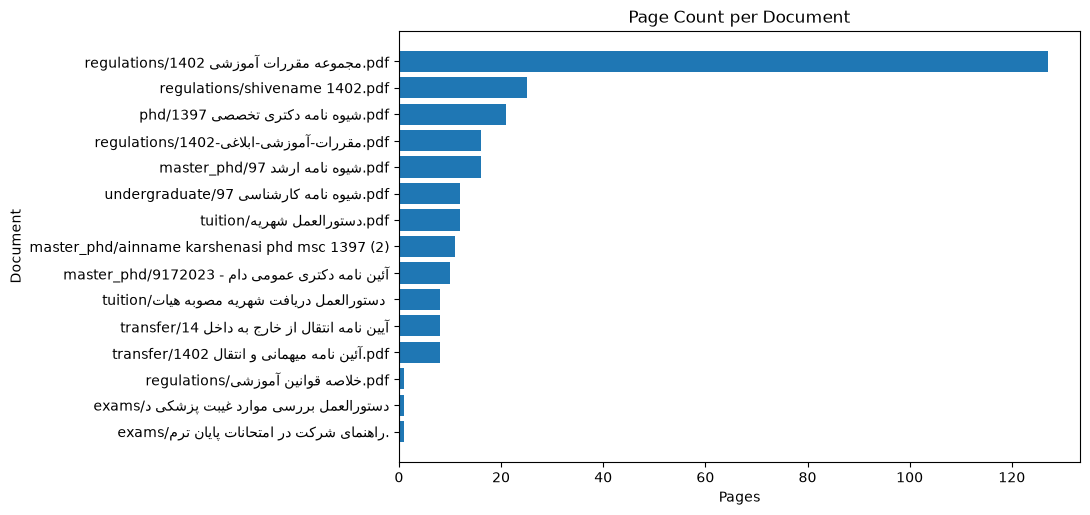

In [25]:
# Plot the page count for each document
if not documents_df.empty:
    plot_df = documents_df.sort_values("page_count")
    labels = [
        f"{row.category}/{row.filename[:35]}"
        for row in plot_df.itertuples()
    ]
    plt.figure(figsize=(11, max(5, len(plot_df) * 0.35)))
    plt.barh(labels, plot_df["page_count"])
    plt.title("Page Count per Document")
    plt.xlabel("Pages")
    plt.ylabel("Document")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "page_count_per_document.png",
        dpi=180, bbox_inches="tight",
    )
    plt.show()

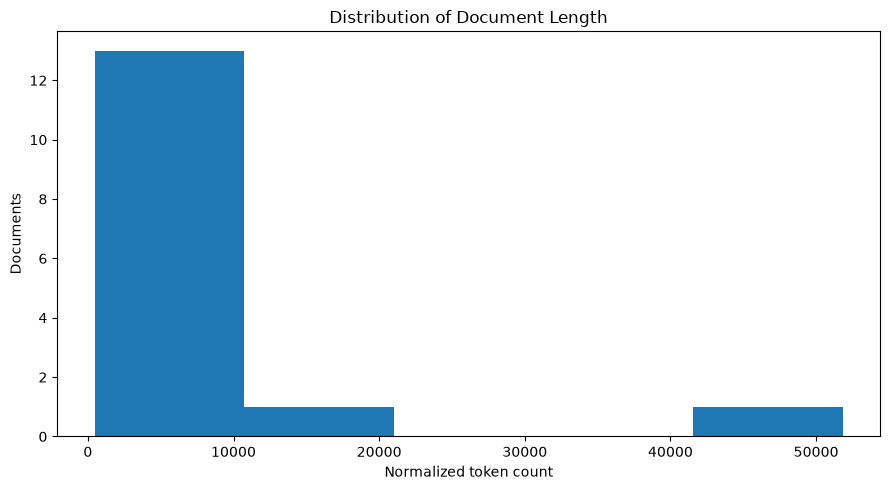

In [26]:
# Plot the document length distribution
if not documents_df.empty:
    plt.figure(figsize=(9, 5))
    bins = min(max(5, int(math.sqrt(len(documents_df)))), 20)
    plt.hist(documents_df["total_tokens"], bins=bins)
    plt.title("Distribution of Document Length")
    plt.xlabel("Normalized token count")
    plt.ylabel("Documents")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "document_length_distribution.png",
        dpi=180, bbox_inches="tight",
    )
    plt.show()

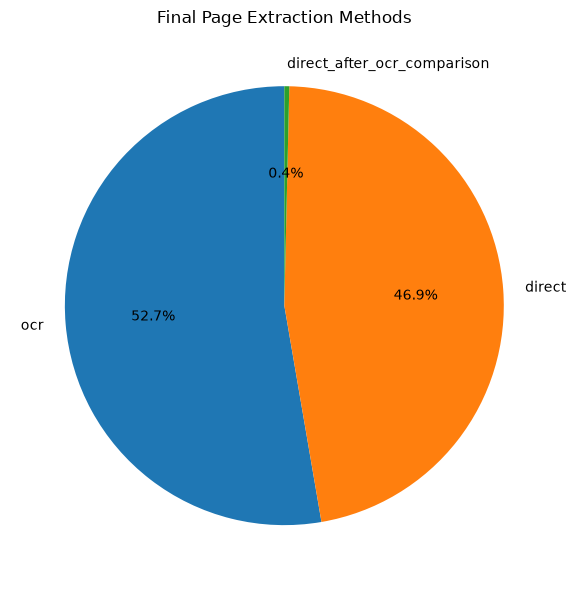

In [27]:
# Plot the final page extraction method ratio
if not pages_df.empty:
    extraction_counts = (
        pages_df["extraction_method"]
        .fillna("unknown")
        .value_counts()
    )
    plt.figure(figsize=(8, 6))
    plt.pie(
        extraction_counts.values,
        labels=extraction_counts.index,
        autopct="%1.1f%%",
        startangle=90,
    )
    plt.title("Final Page Extraction Methods")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "extraction_method_ratio.png",
        dpi=180, bbox_inches="tight",
    )
    plt.show()

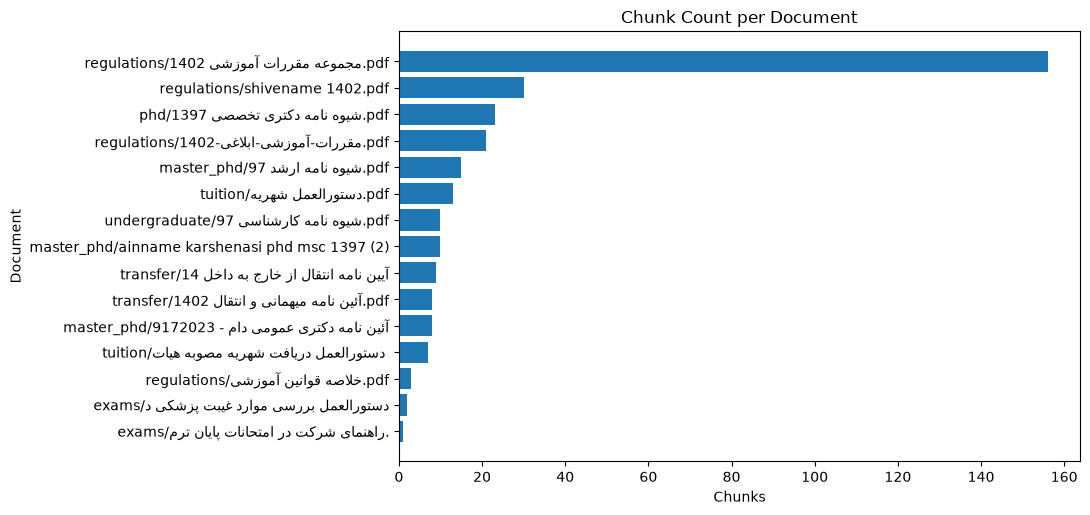

In [28]:
# Plot the chunk count for each document
if not documents_df.empty:
    plot_df = documents_df.sort_values("chunk_count")
    labels = [
        f"{row.category}/{row.filename[:35]}"
        for row in plot_df.itertuples()
    ]
    plt.figure(figsize=(11, max(5, len(plot_df) * 0.35)))
    plt.barh(labels, plot_df["chunk_count"])
    plt.title("Chunk Count per Document")
    plt.xlabel("Chunks")
    plt.ylabel("Document")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "chunk_count_per_document.png",
        dpi=180, bbox_inches="tight",
    )
    plt.show()

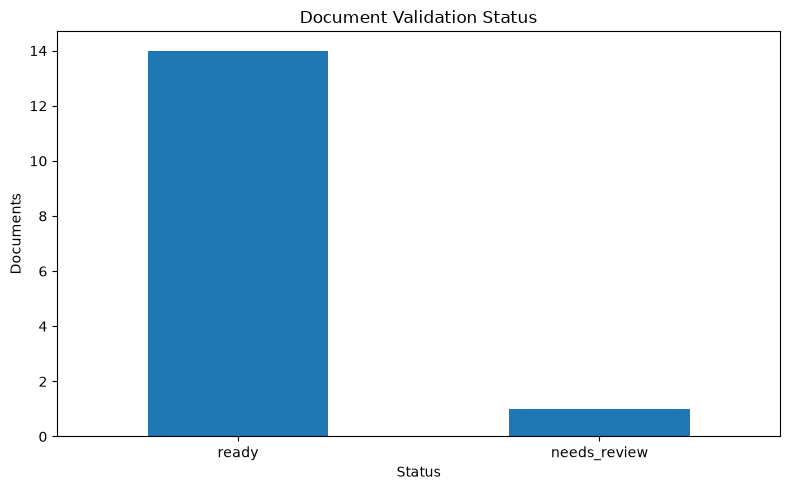

In [29]:
# Plot the document validation status
if not documents_df.empty:
    counts = documents_df["validation_status"].value_counts()
    plt.figure(figsize=(8, 5))
    counts.plot(kind="bar")
    plt.title("Document Validation Status")
    plt.xlabel("Status")
    plt.ylabel("Documents")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / "document_validation_status.png",
        dpi=180, bbox_inches="tight",
    )
    plt.show()

# 12. Final Outputs

The notebook creates:

- `document_catalog.csv`
- `documents.parquet`
- `pages.parquet`
- `chunks.parquet`
- `metadata.json`
- `quality_report.json`
- `execution_report.json`
- `summary.json`
- `final_document_status.csv`
- a pipeline log file


In [30]:
def safe_scalar(value: Any) -> Any:
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return value

def records_json_safe(
    df: pd.DataFrame,
    columns: list[str],
) -> list[dict[str, Any]]:
    available = [x for x in columns if x in df.columns]
    records = df[available].replace({np.nan: None}).to_dict(orient="records")
    return [
        {key: safe_scalar(value) for key, value in record.items()}
        for record in records
    ]

DOCUMENT_METADATA_COLUMNS = [
    "document_id", "title", "publication_year", "category",
    "degree_scope", "document_type", "filename", "relative_path",
    "sha256", "file_size_bytes", "file_size_mb", "page_count",
    "document_pdf_type", "needs_ocr", "ocr_attempted_page_count",
    "ocr_used_page_count", "extraction_methods", "total_tokens",
    "average_page_quality_score", "ready_page_count",
    "review_page_count", "invalid_page_count",
    "validation_status", "chunk_count", "ready_for_retrieval",
]
CHUNK_METADATA_COLUMNS = [
    "chunk_id", "document_id", "chunk_order", "token_count",
    "page_start", "page_end", "page_numbers",
    "structure_type", "structure_number", "structure_label",
    "chapter", "section", "article", "note", "clause",
    "source_unit_orders", "chunk_strategy", "size_status",
    "title", "publication_year", "category", "degree_scope",
    "document_type", "filename", "relative_path",
    "document_pdf_type", "needs_ocr", "extraction_methods",
    "validation_status",
]

METADATA_EXPORT = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": {
        "name": "Shahid Bahonar University of Kerman Education Regulations",
        "url": "https://eduservice.uk.ac.ir/regulations",
    },
    "documents": records_json_safe(
        documents_df, DOCUMENT_METADATA_COLUMNS
    ),
    "chunks": records_json_safe(
        chunks_df, CHUNK_METADATA_COLUMNS
    ),
}

In [31]:
OUTPUT_PATHS = {
    "document_catalog_csv": PROCESSED_DIR / "document_catalog.csv",
    "documents_parquet": PROCESSED_DIR / "documents.parquet",
    "pages_parquet": PROCESSED_DIR / "pages.parquet",
    "chunks_parquet": PROCESSED_DIR / "chunks.parquet",
    "metadata_json": PROCESSED_DIR / "metadata.json",
    "quality_report_json": PROCESSED_DIR / "quality_report.json",
    "execution_report_json": PROCESSED_DIR / "execution_report.json",
    "summary_json": PROCESSED_DIR / "summary.json",
    "final_document_status_csv": PROCESSED_DIR / "final_document_status.csv",
}

with timed_stage("primary_export"):
    catalog_analysis_df.to_csv(
        OUTPUT_PATHS["document_catalog_csv"],
        index=False, encoding="utf-8-sig",
    )
    documents_df.to_parquet(
        OUTPUT_PATHS["documents_parquet"],
        index=False, engine="pyarrow",
    )
    pages_df.to_parquet(
        OUTPUT_PATHS["pages_parquet"],
        index=False, engine="pyarrow",
    )
    chunks_df.to_parquet(
        OUTPUT_PATHS["chunks_parquet"],
        index=False, engine="pyarrow",
    )
    with OUTPUT_PATHS["metadata_json"].open("w", encoding="utf-8") as f:
        json.dump(METADATA_EXPORT, f, ensure_ascii=False, indent=2)
    with OUTPUT_PATHS["quality_report_json"].open("w", encoding="utf-8") as f:
        json.dump(QUALITY_REPORT, f, ensure_ascii=False, indent=2)
    final_status_df.to_csv(
        OUTPUT_PATHS["final_document_status_csv"],
        index=False, encoding="utf-8-sig",
    )

logger.info("Primary outputs exported.")

INFO | START STAGE: primary_export
INFO | END STAGE: primary_export | 0.254 sec
INFO | Primary outputs exported.


# 13. Execution Report and Summary

This section stores:

- Python and package versions
- operating system and Python executable path
- complete configuration
- runtime for every stage and the full pipeline
- errors and warnings
- paths of all generated files
- a short summary for Notebook 02


In [32]:
TOTAL_RUNTIME_SECONDS = round(
    time.perf_counter() - PIPELINE_STARTED_AT, 3
)

EXECUTION_REPORT = {
    **ENVIRONMENT_INFO,
    "run_finished_utc": datetime.now(timezone.utc).isoformat(),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "stage_timings_seconds": STAGE_TIMINGS,
    "config": CONFIG,
    "input": {
        "raw_directory": str(RAW_DIR),
        "categories": CONFIG["categories"],
        "pdf_files_discovered": int(len(catalog_df)),
        "unique_pdf_files": int((~catalog_df["is_duplicate"]).sum()),
    },
    "output_paths": {
        name: str(path) for name, path in OUTPUT_PATHS.items()
    },
    "log_path": str(LOG_PATH),
    "figures_directory": str(FIGURES_DIR),
    "errors": PIPELINE_ERRORS,
    "warnings": PIPELINE_WARNINGS,
}

SUMMARY = {
    "run_id": RUN_ID,
    "status": (
        "completed_with_errors"
        if PIPELINE_ERRORS
        else "completed_with_warnings"
        if PIPELINE_WARNINGS
        else "completed"
    ),
    "documents": int(len(documents_df)),
    "pages": int(len(pages_df)),
    "chunks": int(len(chunks_df)),
    "documents_ready_for_retrieval": int(
        documents_df["ready_for_retrieval"].sum()
    ),
    "documents_needing_review": int(
        (documents_df["validation_status"] == "needs_review").sum()
    ),
    "invalid_documents": int(
        (documents_df["validation_status"] == "invalid").sum()
    ),
    "ocr_used_pages": int(
        (pages_df["extraction_method"] == "ocr").sum()
    ),
    "errors_count": len(PIPELINE_ERRORS),
    "warnings_count": len(PIPELINE_WARNINGS),
    "total_runtime_seconds": TOTAL_RUNTIME_SECONDS,
    "next_notebook_input": str(
        OUTPUT_PATHS["chunks_parquet"]
    ),
}

with OUTPUT_PATHS["execution_report_json"].open("w", encoding="utf-8") as f:
    json.dump(EXECUTION_REPORT, f, ensure_ascii=False, indent=2)

with OUTPUT_PATHS["summary_json"].open("w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2)

logger.info("Execution report and summary saved.")
display(pd.DataFrame([SUMMARY]).T.rename(columns={0: "value"}))

INFO | Execution report and summary saved.


,value
run_id,20260714_232636
status,completed
documents,15
pages,277
chunks,316
documents_ready_for_retrieval,14
documents_needing_review,1
invalid_documents,0
ocr_used_pages,146
errors_count,0


# 14. Final Integrity Check

The notebook checks:

- all required output files exist
- Parquet files can be loaded
- saved row counts match in-memory row counts
- chunk IDs are unique
- no chunk is empty
- no chunk is longer than 500 tokens


In [33]:
required_output_names = [
    "document_catalog_csv", "documents_parquet",
    "chunks_parquet", "metadata_json",
    "quality_report_json", "execution_report_json",
    "summary_json", "final_document_status_csv",
]
missing_outputs = [
    name for name in required_output_names
    if not OUTPUT_PATHS[name].exists()
]
if missing_outputs:
    raise AssertionError(
        f"Required output files were not created: {missing_outputs}"
    )

reloaded_documents = pd.read_parquet(
    OUTPUT_PATHS["documents_parquet"], engine="pyarrow"
)
reloaded_chunks = pd.read_parquet(
    OUTPUT_PATHS["chunks_parquet"], engine="pyarrow"
)

assert len(reloaded_documents) == len(documents_df)
assert len(reloaded_chunks) == len(chunks_df)
assert not reloaded_chunks["chunk_id"].duplicated().any()
assert not (reloaded_chunks["text"].fillna("").str.strip() == "").any()
assert (
    reloaded_chunks["token_count"]
    <= int(CONFIG["chunking"]["max_tokens"])
).all()

print("✅ All required outputs were created and validated.")
for name, path in OUTPUT_PATHS.items():
    marker = "✅" if path.exists() else "❌"
    size = (
        round(path.stat().st_size / (1024 ** 2), 3)
        if path.exists() else None
    )
    print(f"{marker} {name}: {path} | {size} MB")
print("Log:", LOG_PATH)
print("Figures:", FIGURES_DIR)

✅ All required outputs were created and validated.
✅ document_catalog_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\document_catalog.csv | 0.009 MB
✅ documents_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\documents.parquet | 0.733 MB
✅ pages_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\pages.parquet | 1.127 MB
✅ chunks_parquet: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\chunks.parquet | 0.462 MB
✅ metadata_json: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\metadata.json | 0.918 MB
✅ quality_report_json: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\quality_report.json | 0.002 MB
✅ execution_report_json: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\execution_report.json | 0.004 MB
✅ summary_json: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\summary.json | 0.0 MB
✅ final_document_status_csv: D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\final

# 15. Final Status of Each Document


In [34]:
display(final_status_df.style.hide(axis="index"))

Document,Category,Extraction,OCR,Validation,Chunks,Ready
اطالعیه نیمسال پایان امتحانات در دانشجویان شرکت راهنمای,exams,direct,False,ready,1,True
دستورالعمل بررسی موارد غیبت پزشکی در امتحانات پایان ترم (1)پیوست 13 4 1402,exams,direct,False,ready,2,True
ainname karshenasi phd msc 1397 (2),master_phd,ocr,True,ready,10,True
شیوه نامه ارشد 97,master_phd,ocr,True,ready,15,True
لهیا توفیق آرزوی با صدیق خاکی علی شیزموآ ونمعا,master_phd,mixed,True,ready,8,True
شیوه نامه دکتری تخصصی 1397,phd,ocr,True,ready,23,True
shivename 1402,regulations,ocr,True,ready,30,True
شی ز مو آ نینا قو خلاصه تخصصی ی کتر د شد ار شناسی رکا شناسی رکا دوره / ان عنو,regulations,direct,False,ready,3,True
مجموعه مقررات آموزشی 1402,regulations,mixed,True,needs_review,156,False
مقررات آموزشی ابلاغی 1402,regulations,ocr,True,ready,21,True


In [35]:
print("=" * 72)
print("UNIVERSITY RAG — DATA PREPARATION COMPLETED")
print("=" * 72)
print(f"Documents processed : {SUMMARY['documents']}")
print(f"Pages processed     : {SUMMARY['pages']}")
print(f"Chunks generated    : {SUMMARY['chunks']}")
print(f"Ready documents     : {SUMMARY['documents_ready_for_retrieval']}")
print(f"Needs review        : {SUMMARY['documents_needing_review']}")
print(f"Invalid documents   : {SUMMARY['invalid_documents']}")
print(f"OCR pages used      : {SUMMARY['ocr_used_pages']}")
print(f"Errors              : {SUMMARY['errors_count']}")
print(f"Warnings            : {SUMMARY['warnings_count']}")
print(f"Runtime (seconds)   : {SUMMARY['total_runtime_seconds']}")
print(f"Notebook 02 input   : {SUMMARY['next_notebook_input']}")
print("=" * 72)

UNIVERSITY RAG — DATA PREPARATION COMPLETED
Documents processed : 15
Pages processed     : 277
Chunks generated    : 316
Ready documents     : 14
Needs review        : 1
Invalid documents   : 0
OCR pages used      : 146
Errors              : 0
Warnings            : 0
Runtime (seconds)   : 1816.327
Notebook 02 input   : D:\UNI\TERM10\1. NLP\PROJECT\University_RAG\data\processed\chunks.parquet
